# Banking Fraud Detection — Final Notebook

This project explores banking transactions and predicts fraud (`is_fraud`: 1 = fraud, 0 = legitimate). The notebook has four parts:
1. Explore and prepare the dataset (chronological split, train-only EDA, features and preprocessing)
2. Build the models
3. Compare the models
4. Final test evaluation and conclusions

**Protocol.** Split before any sanity check or EDA. Inspect all 44 source columns using **train only**. Validation selects models and thresholds; the test partition is opened once, after every modelling decision is frozen. Heavy plots use at most 200,000 training rows; counts, rates and numeric summaries use all training rows.

**Running the notebook.** It runs locally or on Colab (Drive is optional). Set `RUN_FINAL_TEST` in the configuration cell; keep it `False` while still tuning. Required packages: `lightgbm`, `shap`, `jinja2` (installed in the next cell).

**Dataset source:** https://www.kaggle.com/datasets/orogunadebola/credit-card-transaction-dataset-fraud-detection/data  
**Team Members:** Nguyễn Thị Thùy Linh, Lê Hải Đông Nghi, Đinh Hải Yên


In [ ]:
import os, hashlib, shutil
import gc
import time
import json
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pyarrow.parquet as pq
from IPython.display import display, Markdown
try:
    from google.colab import drive
except ImportError:
    drive = None

import sklearn
import scipy
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import precision_recall_curve, roc_auc_score, average_precision_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB

import lightgbm as lgb


In [ ]:
%matplotlib inline
pd.set_option('display.max_rows', 60)
sns.set_theme(style='whitegrid')
USE_DRIVE = drive is not None
RUN_FINAL_TEST = True   # True only for the final run: scores the frozen model on the held-out test set once.
CHUNK_SIZE = 200_000

SEED = 42
N_CV = 300_000          # most recent training rows used for temporal CV
N_ABL = 600_000         # rows used for the protocol ablation
SGD_MAX_ITER = 100      # same for every SGD model (logistic, SVM, CV baseline)
COST_FP = 45.0          # ASSUMPTION: cost of one false alarm (review/friction), in the currency of `amt`
COST_FP_GRID = [10, 45, 100, 250]   # sensitivity check for the assumption above


In [ ]:
# Colab only: edit this path if your Drive layout differs.
DRIVE_PROJECT_DIR = '/content/drive/MyDrive/Banking_Fraud_Midterm_Member1/GitHub_Review'
if USE_DRIVE:
    drive.mount('/content/drive')
    root = Path(DRIVE_PROJECT_DIR)
else:
    root = Path.cwd()
csv_path = Path(os.environ.get('FRAUD_DATA_CSV', str(root / 'data/raw/data.csv')))
if USE_DRIVE and not csv_path.exists():
    csv_path = root.parent / 'Handoff_Outputs/raw_input_data/data.csv'
assert csv_path.is_file(), 'Place data.csv in data/raw or set FRAUD_DATA_CSV.'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
output = root / 'data/processed'
results_dir = root / 'results'
output.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
metadata = pd.read_csv(root / 'data/data_dictionary.csv')
assert set(metadata.columns) == {'column', 'group', 'description', 'unit_or_encoding'}


Drive users may copy the large CSV to the runtime once, reducing repeated Drive reads. This is a temporary runtime copy. Local execution uses the CSV directly.


In [ ]:
if USE_DRIVE:
    runtime_csv = Path('/content/banking_fraud_runtime/data.csv')
    runtime_csv.parent.mkdir(parents=True, exist_ok=True)
    shutil.copyfile(csv_path, runtime_csv)
    csv_path = runtime_csv


# 1. Explore and Prepare the Dataset
## 1.1 Load and Split Before Analysis
The first pass reads **only source date and time**. These fields establish chronological membership; no target values, distributions or feature statistics are inspected. Equal timestamps stay together.

Use about 80% for development and 20% for test; reserve the last 20% of development for validation (about 64/16/20 overall).


In [ ]:
time_parts, offset = [], 0
for chunk in pd.read_csv(csv_path, usecols=['trans_date', 'trans_time'], chunksize=CHUNK_SIZE):
    event_time = pd.to_datetime(chunk['trans_date'] + ' ' + chunk['trans_time'], errors='raise')
    time_parts.append(pd.DataFrame({'source_row': np.arange(offset, offset + len(chunk), dtype='int32'),
                                    'datetime': event_time}))
    offset += len(chunk)
timeline = pd.concat(time_parts, ignore_index=True).sort_values(['datetime', 'source_row']).reset_index(drop=True)
del time_parts, chunk, event_time
gc.collect()


94

In [ ]:
n = len(timeline)
times = timeline['datetime']
test_start = times.searchsorted(times.iloc[int(n * 0.80)], side='left')
validation_start = times.searchsorted(times.iloc[int(test_start * 0.80)], side='left')
slices = {'train': (0, validation_start), 'validation': (validation_start, test_start), 'test': (test_start, n)}
train_row_ids = timeline.iloc[:validation_start]['source_row'].to_numpy()
split_by_row = np.full(n, 2, dtype='int8')
split_by_row[timeline.iloc[:test_start]['source_row'].to_numpy()] = 1
split_by_row[train_row_ids] = 0


In [ ]:
split_rows = []
for name, (start, end) in slices.items():
    split_rows.append([name, end-start, times.iloc[start], times.iloc[end-1]])
split_summary = pd.DataFrame(split_rows, columns=['split', 'n', 'start', 'end'])
split_summary.to_csv(output / 'split_summary.csv', index=False)
assert times.iloc[validation_start-1] < times.iloc[validation_start]
assert times.iloc[test_start-1] < times.iloc[test_start]
split_summary


,split,n,start,end
0,train,5491362,2022-05-07 00:00:01,2022-12-15 16:00:01
1,validation,1372841,2022-12-15 16:00:05,2023-02-11 19:16:00
2,test,1716052,2023-02-11 19:16:02,2023-05-07 23:59:59


**Chronological split**
- Train has 5.49M rows (2022-05-07 → 2022-12-15), validation 1.37M (→ 2023-02-11), test 1.72M (→ 2023-05-07): roughly 64/16/20, and the cut points do not fall inside a shared timestamp (asserted in code).
- This mimics real deployment (train on the past, predict the future) and is the notebook's biggest methodological strength. Splitting *before* EDA also prevents information leakage.
- Caveat: validation spans only ~2 months and test ~3 months, so results reflect one specific period rather than all seasons.

The table reports only split sizes and time ranges. It deliberately does **not** report validation/test fraud counts or rates. CSV parsing is not EDA; subsequent statistics use the training partition only.


In [ ]:
id_types = dict.fromkeys(['ssn', 'cc_num', 'zip', 'acct_num', 'trans_num'], 'string[pyarrow]')
train_parts, offset = [], 0
for chunk in pd.read_csv(csv_path, dtype=id_types, dtype_backend='pyarrow', chunksize=CHUNK_SIZE):
    row_ids = np.arange(offset, offset + len(chunk), dtype='int32')
    keep = split_by_row[row_ids] == 0
    part = chunk.loc[keep].copy()
    part.index = row_ids[keep]
    train_parts.append(part)
    offset += len(chunk)
train = pd.concat(train_parts).loc[train_row_ids]
del train_parts, chunk, part, row_ids, keep
gc.collect()


0

In [ ]:
raw_columns = train.columns.tolist()
assert len(raw_columns) == 44 and set(raw_columns) == set(metadata['column'])
category_columns = ['ssn', 'cc_num', 'first', 'last', 'street', 'city', 'state', 'zip',
                    'job', 'acct_num', 'profile', 'category', 'merchant', 'gender']
for column in category_columns:
    train[column] = train[column].astype('category')
train['datetime'] = pd.to_datetime(train['trans_date'] + ' ' + train['trans_time'])
assert len(train) == validation_start
assert train['datetime'].max() < times.iloc[validation_start]
print('Training rows:', len(train), '| original columns:', len(raw_columns))


Training rows: 5491362 | original columns: 44


## 1.2 Sanity Checks — Train Only
Read column meanings from the static dictionary. Recompute types, missingness, distinct counts and numeric summaries directly on train; no precomputed `_full.csv` files are loaded.


In [ ]:
profile = pd.DataFrame({'dtype': train[raw_columns].dtypes.astype(str),
                        'missing': train[raw_columns].isna().sum(),
                        'unique': train[raw_columns].nunique()})
profile['missing_pct'] = profile['missing'] / len(train) * 100
profile.index.name = 'column'
dictionary = metadata.merge(profile.reset_index(), on='column', validate='one_to_one')
dictionary[['column', 'group', 'dtype', 'unique', 'missing_pct']]


,column,group,dtype,unique,missing_pct
0,ssn,Identifiers,category,9460,0.0
1,cc_num,Identifiers,category,9460,0.0
2,first,Identifiers,category,660,0.0
3,last,Identifiers,category,984,0.0
4,gender,Customer,category,2,0.0
5,street,Identifiers,category,9460,0.0
6,city,Customer,category,3585,0.0
7,state,Customer,category,51,0.0
8,zip,Identifiers,category,6572,0.0
9,lat,Customer,double[pyarrow],6434,0.0


In [ ]:
numeric_columns = train[raw_columns].select_dtypes('number').columns.tolist()
numeric = train[numeric_columns].describe().T
numeric['unique'] = train[numeric_columns].nunique()
print('Repeated training transaction IDs:', train['trans_num'].duplicated().sum())
print('Training missing cells:', int(profile['missing'].sum()))
numeric[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2)


Repeated training transaction IDs: 0
Training missing cells: 0


,count,mean,std,min,25%,50%,75%,max
lat,5491362.0,37.45,5.23,19.44,33.82,38.42,41.12,64.85
long,5491362.0,-92.17,16.62,-162.17,-98.69,-87.45,-80.06,-67.47
city_pop,5491362.0,290827.98,560148.11,89.0,17603.0,60763.0,229807.0,2906700.0
unix_time,5491362.0,1661607948.02,5716746.68,1651878001.0,1656672285.75,1661217475.0,1666685771.25,1671116401.0
amt,5491362.0,76.23,155.65,1.0,9.61,51.1,84.59,27825.47
is_fraud,5491362.0,0.01,0.1,0.0,0.0,0.0,0.0,1.0
merch_lat,5491362.0,37.45,5.26,18.44,33.72,38.3,41.24,65.85
merch_long,5491362.0,-92.17,16.63,-163.15,-98.99,-87.22,-79.86,-66.48
customer_num_trans_1_day,5491362.0,3.0,2.0,0.0,1.0,3.0,5.0,6.0
customer_num_trans_7_day,5491362.0,5.5,2.63,0.0,4.0,6.0,7.0,11.0


**Training-data quality checks**

- No missing values or duplicate `trans_num` values were found; `is_fraud` contains only 0/1 labels, transaction amounts are non-negative, and the recorded coordinates pass the implemented validity checks.
- `amt` is strongly right-skewed (mean ≈ 76, standard deviation ≈ 156, maximum ≈ 27,825), making `log1p(amt)` a reasonable candidate transformation.
- The unusually clean structure and several source inconsistencies identified below suggest that the dataset may be synthetic or generator-derived. This is an inference from the observed data, not a confirmed statement about its provenance.

In [ ]:
dictionary.groupby('group', sort=False)['column'].count().rename('columns')


,columns
group,
Identifiers,8
Customer,9
Transaction,6
Merchant,3
Customer history,6
Supplied time features,5
Merchant history,7


In [ ]:
dictionary[['column', 'description', 'unit_or_encoding']]


,column,description,unit_or_encoding
0,ssn,Customer identifier; exact semantics unverified,identifier
1,cc_num,Payment card identifier; preserve precision,identifier
2,first,Given name,text
3,last,Family name,text
4,gender,Recorded gender; source definitions unverified,source codes
5,street,Street address,text
6,city,Customer city,text
7,state,Recorded state/region,source codes
8,zip,Postal code; raw leading zeros may already be ...,postal code
9,lat,"Customer latitude, interpreted from column name",degrees


In [ ]:
fixed_attributes = ['ssn', 'acct_num', 'first', 'last', 'gender', 'street', 'city', 'state',
                    'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'profile']
conflicts = train.groupby('cc_num', observed=True)[fixed_attributes].nunique().gt(1).sum()
conflicts.rename('cards_with_multiple_values_in_train')


,cards_with_multiple_values_in_train
ssn,0
acct_num,0
first,0
last,0
gender,0
street,0
city,0
state,0
zip,0
lat,0


Each `cc_num` maps consistently to one `ssn`, `acct_num`, name, address, date of birth, and related profile fields in the checked training data. The 9,460 distinct cards therefore correspond to 9,460 distinct customer profiles in this dataset. Identifier columns are excluded from direct model inputs to reduce the risk of memorizing entities; `cc_num` is retained only to construct point-in-time card-history features.

In [ ]:
lengths = pd.DataFrame()
for column in ['ssn', 'cc_num', 'zip', 'acct_num', 'trans_num']:
    lengths[column] = train[column].astype('string[pyarrow]').str.len().agg(['min', 'max'])
lengths.T.rename(columns={'min': 'min_length_train', 'max': 'max_length_train'})


,min_length_train,max_length_train
ssn,11,11
cc_num,11,19
zip,4,5
acct_num,9,12
trans_num,32,32


`zip` has 4–5 characters (leading zeros already lost) and `cc_num` has 11–19. Reading these columns as strings is necessary to avoid precision loss. A technical check only; it does not affect the model since these columns are not features.

In [ ]:
event = train['datetime']
birth = pd.to_datetime(train['dob'], errors='coerce')
seconds = event.dt.hour*3600 + event.dt.minute*60 + event.dt.second
night = (event.dt.hour >= 22) | (event.dt.hour < 6)
time_checks = pd.Series({'invalid_dob': birth.isna().sum(), 'birth_after_transaction': birth.gt(event).sum(),
    'hour_mismatch': train['trans_time_hrs'].ne(event.dt.hour).sum(),
    'seconds_mismatch': train['trans_time_secs'].ne(seconds).sum(),
    'weekday_mismatch_monday0': train['trans_time_day'].ne(event.dt.dayofweek).astype(int).sum(),
    'weekend_mismatch': train['trans_date_is_weekend'].ne((event.dt.dayofweek >= 5).astype(int)).sum(),
    'night_mismatch_assuming_22_to_5': train['trans_time_is_night'].ne(night.astype(int)).sum()})
time_checks.rename('affected_training_rows').to_frame()


,affected_training_rows
invalid_dob,0
birth_after_transaction,0
hour_mismatch,5263122
seconds_mismatch,5491294
weekday_mismatch_monday0,0
weekend_mismatch,0
night_mismatch_assuming_22_to_5,2453401


In [ ]:
epoch = pd.to_datetime(train['unix_time'], unit='s', errors='coerce', utc=True)
epoch_offsets = (event.dt.tz_localize('UTC') - epoch).dt.total_seconds().value_counts(dropna=False)
epoch_offsets.rename_axis('offset_seconds').rename('training_rows')


,training_rows
offset_seconds,
3600.0,5491362


**The supplied time fields are unreliable**
- `trans_time_hrs` disagrees with the hour recomputed from `trans_date + trans_time` in **5.26M of 5.49M rows**, and `trans_time_is_night` disagrees in 2.45M rows. The next table shows `unix_time` is always offset by exactly **3,600 s** from `trans_time`, so the supplied hour fields live in a different time zone.
- Weekday/weekend flags match 100%.
- Recomputing the hour from the raw date + time and discarding the supplied fields is the right call. The notebook also honestly admits the true time zone is unknown.

In [ ]:
numeric_checks = pd.Series({'invalid_target': (~train['is_fraud'].isin([0, 1])).sum(),
    'negative_amount': train['amt'].lt(0).sum(), 'invalid_customer_lat': train['lat'].abs().gt(90).sum(),
    'invalid_customer_long': train['long'].abs().gt(180).sum(),
    'invalid_merchant_lat': train['merch_lat'].abs().gt(90).sum(),
    'invalid_merchant_long': train['merch_long'].abs().gt(180).sum()})
for who in ['customer', 'merchant']:
    numeric_checks[who+'_count_1d_gt_7d'] = train[who+'_num_trans_1_day'].gt(train[who+'_num_trans_7_day']).sum()
    numeric_checks[who+'_count_7d_gt_30d'] = train[who+'_num_trans_7_day'].gt(train[who+'_num_trans_30_day']).sum()
numeric_checks.rename('affected_training_rows').to_frame()


,affected_training_rows
invalid_target,0
negative_amount,0
invalid_customer_lat,0
invalid_customer_long,0
invalid_merchant_lat,0
invalid_merchant_long,0
customer_count_1d_gt_7d,0
customer_count_7d_gt_30d,0
merchant_count_1d_gt_7d,90747
merchant_count_7d_gt_30d,205945


In [ ]:
count_columns = [c for c in raw_columns if '_num_trans_' in c]
count_values = train[count_columns].astype('float64')
fractional = count_values.mod(1).ne(0).sum().rename('fractional_rows').to_frame()
del count_values
fractional['percent_of_train'] = fractional['fractional_rows'] / len(train) * 100
fractional


,fractional_rows,percent_of_train
customer_num_trans_1_day,0,0.000000
customer_num_trans_7_day,0,0.000000
customer_num_trans_30_day,0,0.000000
merchant_num_trans_1_day,5436126,98.994129
merchant_num_trans_7_day,5436535,99.001577
merchant_num_trans_30_day,5436672,99.004072


**Merchant history columns are broken**
- `merchant_num_trans_1_day` > `7_day` in 90,747 rows and `7_day` > `30_day` in 205,945 rows. This is impossible for cumulative counters (a 1-day window cannot exceed a 7-day window).
- About 99% of merchant counts are fractional, although a transaction count must be an integer.
- Customer counts are consistent (correct ordering, all integers).
- Reasonable conclusion: do not use the raw history columns; use the self-computed features of Section 1.10b instead.

**Interpretation:** Missingness is separate from correctness. Coordinate and count-window checks are sanity checks; history definitions remain unverified. The night check assumes 22:00–05:59, and the epoch comparison assumes the source clock is UTC only for comparison. Neither establishes the true timezone.


## 1.3 Customer Demographics and Population — Train
Age is measured at the transaction date. Counts and rates below use all train rows. Heavy plots use a reproducible training sample.


In [ ]:
before_birthday = (event.dt.month < birth.dt.month) | ((event.dt.month == birth.dt.month) & (event.dt.day < birth.dt.day))
train['age'] = (event.dt.year - birth.dt.year - before_birthday.astype(int)).astype('float32')
train.groupby('is_fraud', observed=True)['age'].describe().round(2)


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,5433253.0,43.85,17.82,13.0,30.0,41.0,55.0,95.0
1,58109.0,48.30,19.09,14.0,33.0,48.0,62.0,95.0


In [ ]:
ages = train.assign(age_group=pd.cut(train['age'], [0, 18, 25, 50, 65, 100], right=False))
age_counts = ages.groupby(['age_group', 'is_fraud'], observed=True).size().unstack(fill_value=0)
age_counts['fraud_pct'] = age_counts[1] / age_counts[[0, 1]].sum(axis=1) * 100
del ages
age_counts


is_fraud,0,1,fraud_pct
age_group,,,
"[0, 18)",62400,672,1.065449
"[18, 25)",625427,6363,1.007138
"[25, 50)",3048898,24001,0.781054
"[50, 65)",935018,15295,1.609470
"[65, 100)",761510,11778,1.523107


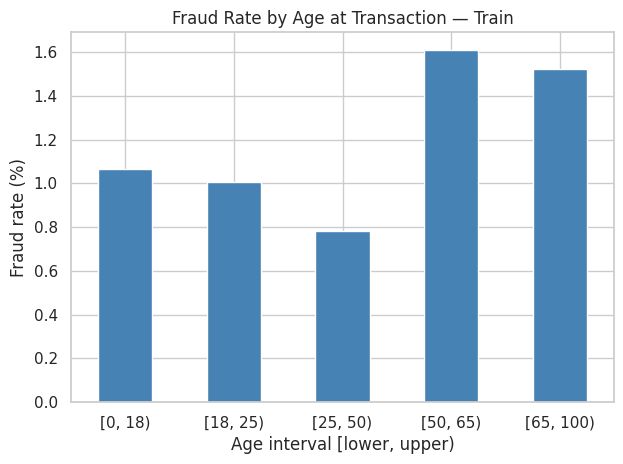

In [ ]:
age_counts['fraud_pct'].plot(kind='bar', color='steelblue', rot=0)
plt.title('Fraud Rate by Age at Transaction — Train')
plt.ylabel('Fraud rate (%)'); plt.xlabel('Age interval [lower, upper)')
plt.tight_layout(); plt.show()


### Observations: Fraud Rate by Age Group

- The observed fraud rate is higher for customers aged 50 and above, peaking at approximately **1.5%–1.6%** in the displayed age groups.
- The 25–50 age group has the lowest observed rate, at approximately **0.78%**.
- These are descriptive differences in the training partition. They do not establish that age causes fraud, and the source-generation process for demographic fields has not been verified.

In [ ]:
gender = pd.crosstab(train['gender'], train['is_fraud'])
gender['n'] = gender[[0, 1]].sum(axis=1)
gender['fraud_pct'] = gender[1] / gender['n'] * 100
gender


is_fraud,0,1,n,fraud_pct
gender,,,,
F,2725723,28673,2754396,1.040990
M,2707530,29436,2736966,1.075497


**Gender summary:** The observed fraud rates for women (1.041%) and men (1.075%) are very similar. The chi-square test in Section 1.9 gives a small p-value, but Cramér's V is only about 0.0017, indicating a negligible association in magnitude. Gender is retained for descriptive analysis only and is not used as a model feature.

In [ ]:
category_tables = []
for column in ['city', 'state', 'job', 'profile', 'category', 'merchant']:
    table = train[column].value_counts().rename('n').rename_axis('value').reset_index()
    table.insert(0, 'column', column)
    category_tables.append(table)
category_counts = pd.concat(category_tables, ignore_index=True)
category_counts.groupby('column', sort=False).head(10)


,column,value,n
0,city,Houston,53266
1,city,Chicago,51529
2,city,Brooklyn,47272
3,city,Los Angeles,39384
4,city,New York City,31398
5,city,Dallas,27230
6,city,Philadelphia,26724
7,city,Denver,25618
8,city,Bronx,23778
9,city,Las Vegas,23297


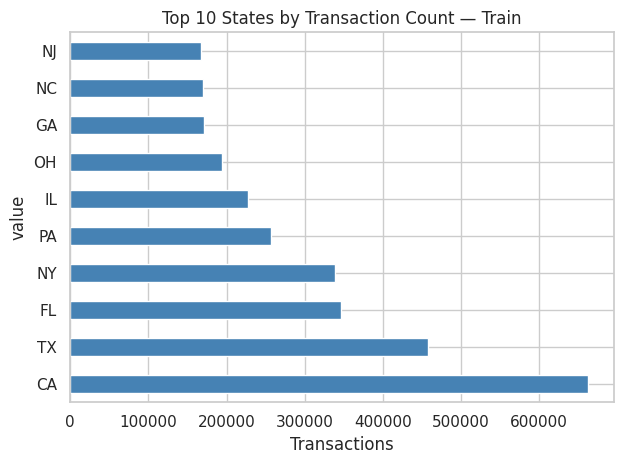

In [ ]:
state_counts = category_counts[category_counts['column'].eq('state')].nlargest(10, 'n')
state_counts.set_index('value')['n'].plot(kind='barh', color='steelblue')
plt.title('Top 10 States by Transaction Count — Train')
plt.xlabel('Transactions'); plt.tight_layout(); plt.show()


**City and state distribution:** California, Texas, Florida, New York, and Pennsylvania have the largest transaction volumes, which may partly reflect population and activity levels. Transaction volume should not be interpreted as fraud risk. State indicators have relatively small contributions in the current SHAP analysis, but that alone is not sufficient evidence to remove them without a controlled comparison.

In [ ]:
train.groupby('profile', observed=True)['is_fraud'].agg(n='size', fraud_rate='mean')


,n,fraud_rate
profile,,
adults_2550_female_rural.json,59050,0.009619
adults_2550_female_urban.json,1493324,0.006784
adults_2550_male_rural.json,58702,0.010715
adults_2550_male_urban.json,1500468,0.008287
adults_50up_female_rural.json,56999,0.011193
adults_50up_female_urban.json,850522,0.016649
adults_50up_male_rural.json,52885,0.009076
adults_50up_male_urban.json,816614,0.015586
young_adults_female_rural.json,15752,0.010348


**Profile summary:** Observed fraud rates range from approximately 0.68% for urban women aged 25–50 to 1.66% for urban women over 50. This variation is descriptive and may partly reflect how the dataset was generated. Because the provenance of `profile` is unverified, it is excluded from the model inputs rather than treated as a reliable predictor.

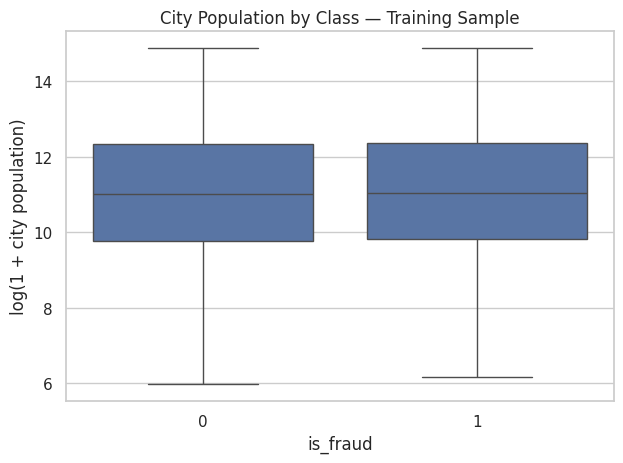

In [ ]:
data = train.sample(n=min(200_000, len(train)), random_state=42).copy()
data['log_city_pop'] = np.log1p(data['city_pop'])
sns.boxplot(data=data, x='is_fraud', y='log_city_pop', showfliers=False)
plt.title('City Population by Class — Training Sample')
plt.ylabel('log(1 + city population)'); plt.tight_layout(); plt.show()


**City population:** The fraud and legitimate distributions of `log_city_pop` look similar in this univariate plot. A feature can nevertheless contribute conditionally through interactions with other variables; the SHAP analysis later suggests a modest conditional contribution. This should not be interpreted as evidence that city population is independently predictive or causal.

Counts measure transaction exposure, not causal state-level risk. Gender remains EDA-only. Raw history/profile columns stay out of the model because their source definitions are unconfirmed; Section 1.10 instead derives verifiable card-history features from `cc_num` and timestamps.


## 1.4 Merchant and Geographic Information — Train
Inspect coordinate ranges on train and use the training sample for heavy geographic plots.


In [ ]:
numeric.loc[['lat', 'long', 'merch_lat', 'merch_long'], ['min', '50%', 'max']]


,min,50%,max
lat,19.4386,38.4161,64.8544
long,-162.1739,-87.4539,-67.4722
merch_lat,18.439186,38.304514,65.850696
merch_long,-163.146675,-87.218832,-66.476814


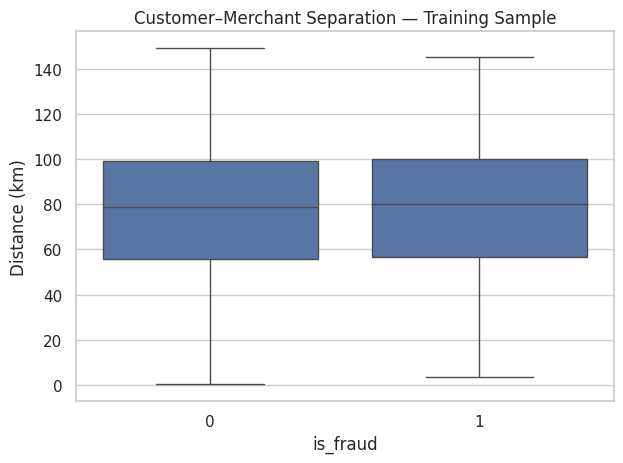

In [ ]:
lat1, lat2 = np.radians(data['lat']), np.radians(data['merch_lat'])
dlat = lat2 - lat1
dlon = np.radians(data['merch_long'] - data['long'])
a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
data['distance_km'] = 6371.0088 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))
sns.boxplot(data=data, x='is_fraud', y='distance_km', showfliers=False)
plt.title('Customer–Merchant Separation — Training Sample')
plt.ylabel('Distance (km)'); plt.tight_layout(); plt.show()


**Customer–merchant distance:** The median recorded distance is approximately 79 km for fraud and 78 km for legitimate transactions, and the distributions overlap substantially. The observed maximum is around 150 km. These patterns may reflect the dataset's construction and do not establish how far real cardholders travel. Distance has low importance in the fitted model and is retained only as a derived feature in the current specification.

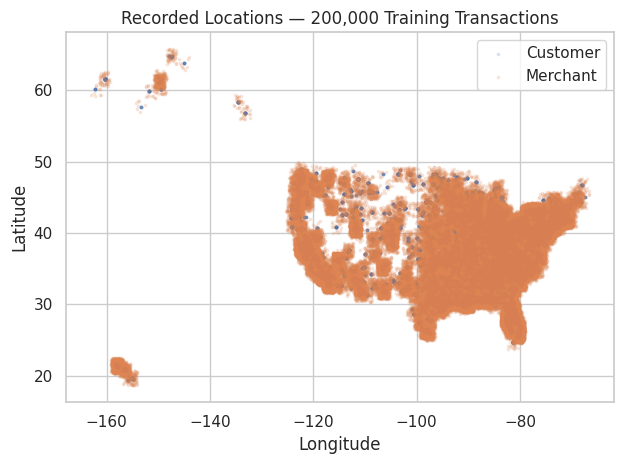

In [ ]:
plt.scatter(data['long'], data['lat'], s=3, alpha=0.15, label='Customer')
plt.scatter(data['merch_long'], data['merch_lat'], s=3, alpha=0.15, label='Merchant')
plt.title(f'Recorded Locations — {len(data):,} Training Transactions')
plt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.legend()
plt.tight_layout(); plt.show()


**Location map:** The recorded data cover the contiguous United States, Alaska, and Hawaii. Customer and merchant points overlap substantially, which is consistent with the similar distance distributions observed above. Block-like geographic patterns may reflect regionalized or synthetic coordinate generation, but the source of these patterns cannot be confirmed from the plot alone.

### Observations: Geographic Distribution and Distance

- Customer and merchant coordinates cover the contiguous United States as well as Alaska and Hawaii, with many observations concentrated in populated regions.
- The recorded customer–merchant distances are similar for fraudulent and legitimate transactions. This is a descriptive result; it does not establish that the two groups have identical geographic behaviour.
- Coordinate patterns may reflect the source dataset's generation process. `distance_km` measures separation between recorded coordinates, not an observed journey or verified customer location.

In [ ]:
merchant_counts = category_counts[category_counts['column'].eq('merchant')]
display(merchant_counts.nlargest(10, 'n'))
train.assign(has_fraud_prefix=train['merchant'].astype('string').str.startswith('fraud_')).groupby('is_fraud', observed=True)['has_fraud_prefix'].mean()


,column,value,n
4301,merchant,fraud_Kilback LLC,25839
4302,merchant,fraud_Kuhn LLC,24590
4303,merchant,fraud_Boyer PLC,24015
4304,merchant,fraud_Turner and Sons,17098
4305,merchant,"fraud_Bahringer, Schoen and Corkery",17027
4306,merchant,fraud_Macejkovic-Lesch,17020
4307,merchant,"fraud_Douglas, Schneider and Turner",17005
4308,merchant,"fraud_Okuneva, Schneider and Rau",16974
4309,merchant,fraud_Friesen Inc,16962
4310,merchant,fraud_Pagac LLC,16961


,has_fraud_prefix
is_fraud,
0,1.0
1,1.0


**Merchant-name prefix check:** All observed merchant names in both classes begin with `fraud_`. Because the prefix occurs for both legitimate and fraudulent transactions, it does not distinguish the target in this dataset. The `merchant` field is excluded from model inputs, so it is not used by the classifier.

## 1.5 Transaction, Time and Category Features — Train
Every class count, rate and category/time table in this section uses train only.


,n,percent
is_fraud,,
0,5433253,98.941811
1,58109,1.058189


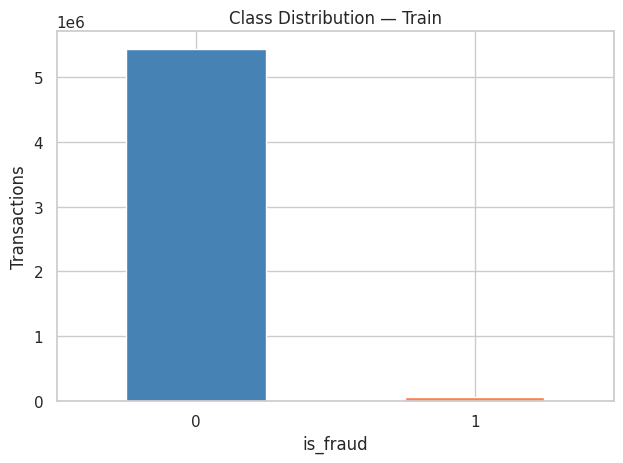

In [ ]:
labels = train['is_fraud'].value_counts().sort_index().rename('n').to_frame()
labels['percent'] = labels['n'] / len(train) * 100
display(labels)
labels['n'].plot(kind='bar', color=['steelblue', 'coral'], rot=0)
plt.title('Class Distribution — Train'); plt.ylabel('Transactions')
plt.tight_layout(); plt.show()


**Class distribution:** The training partition contains approximately 98.94% legitimate transactions and 1.06% fraud (about 93:1). Accuracy alone would be misleading in this imbalanced setting, so average precision (reported as PR-AUC in this notebook), precision, recall, F1-score, and ROC-AUC are reported together. The observed fraud rate increases from 1.06% in training to 1.15% in validation and 1.22% in test; this may affect performance at a fixed threshold.

,n,minimum,median,maximum
is_fraud,,,,
0,5433253,1.0,50.69,27825.47
1,58109,1.07,458.69,1418.81


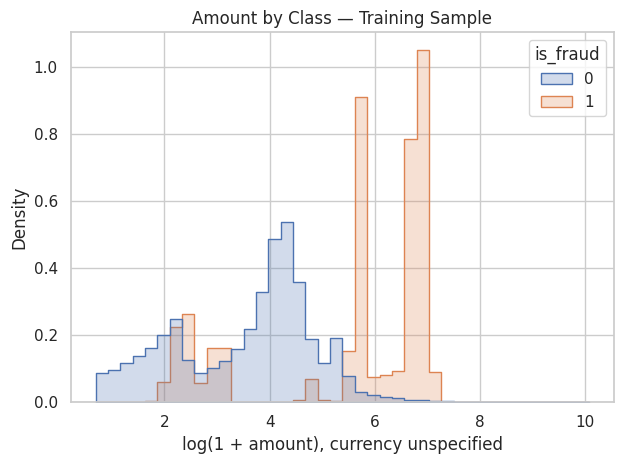

In [ ]:
amount_by_label = train.groupby('is_fraud', observed=True)['amt'].agg(n='size', minimum='min', median='median', maximum='max')
display(amount_by_label)
data['log_amount'] = np.log1p(data['amt'])
sns.histplot(data=data, x='log_amount', hue='is_fraud', bins=40,
             stat='density', common_norm=False, element='step')
plt.title('Amount by Class — Training Sample')
plt.xlabel('log(1 + amount), currency unspecified'); plt.tight_layout(); plt.show()


**Transaction amount**

- The median amount is **458.69** for fraudulent transactions and **50.69** for legitimate transactions in the training partition.
- The largest fraudulent amount observed in training is approximately **1,418.81**, while legitimate transactions extend to approximately **27,825**. This is a pattern in the training data only; it must not be treated as a guaranteed rule for future transactions.
- The distribution shows pronounced concentrations around log amounts corresponding roughly to 300 and 900, plus a smaller low-amount cluster. Such sharp patterns may reflect dataset-generation rules and warrant caution when generalizing.
- `log_amount` is highly influential in the fitted model. The low-amount fraud cluster may be harder to distinguish, but that hypothesis has not been directly tested.

In [ ]:
hour_stats_train = train.groupby(train['datetime'].dt.hour, observed=True)['is_fraud'].agg(n='size', fraud='sum')
hour_stats_train['fraud_pct'] = hour_stats_train['fraud'] / hour_stats_train['n'] * 100
hour_stats_train


,n,fraud,fraud_pct
datetime,,,
0,276723,5353,1.934425
1,276596,5209,1.883252
2,278143,5161,1.85552
3,277845,5354,1.926974
4,272490,408,0.14973
5,273158,418,0.153025
6,272367,422,0.154938
7,272494,405,0.148627
8,271815,397,0.146055


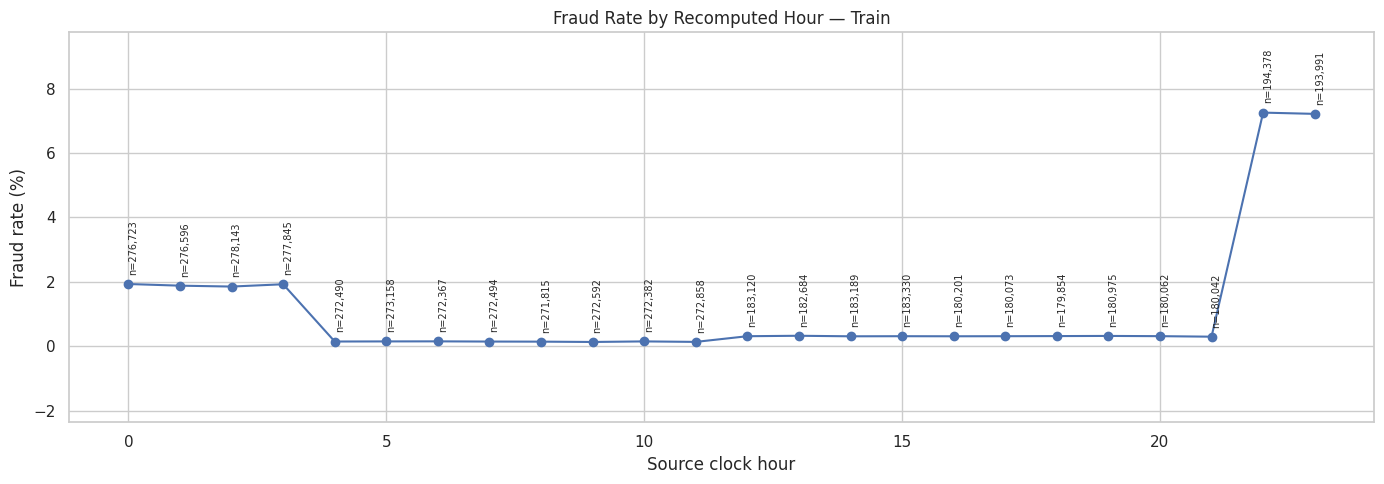

In [ ]:
ax = hour_stats_train['fraud_pct'].plot(marker='o', figsize=(14, 5))
for hour, row in hour_stats_train.iterrows():
    ax.annotate(f"n={int(row['n']):,}", (hour, row['fraud_pct']), rotation=90, fontsize=7,
                xytext=(0, 8), textcoords='offset points')
ax.margins(y=0.35); plt.title('Fraud Rate by Recomputed Hour — Train')
plt.ylabel('Fraud rate (%)'); plt.xlabel('Source clock hour'); plt.tight_layout(); plt.show()


**Fraud rate by hour**

- The observed fraud rate is approximately 7.2% at hours 22–23, around 1.9% at hours 0–3, and approximately 0.14%–0.33% at hours 4–21.
- Hours 22–3 account for about 27% of transactions but approximately 85% of training fraud cases (49,173 of 58,109).
- The sharp changes at particular hours may indicate generator-specific patterns rather than stable real-world behaviour.
- Hour-of-day features are useful to the fitted model, but the source timezone is unknown, so the interpretation of these hours is limited.

In [ ]:
category_train = train.groupby('category', observed=True)['is_fraud'].agg(n='size', fraud='sum')
category_train['non_fraud'] = category_train['n'] - category_train['fraud']
category_train['fraud_pct'] = category_train['fraud'] / category_train['n'] * 100
category_train.sort_values('fraud_pct', ascending=False)


,n,fraud,non_fraud,fraud_pct
category,,,,
home,1314,1314,0,100.0
kids_pets,1378,1378,0,100.0
personal_care,1538,1538,0,100.0
travel,960,960,0,100.0
shopping_net,627365,13727,613638,2.18804
health_fitness,44077,932,43145,2.114481
misc_net,390473,7477,382996,1.914857
grocery_pos,809773,13562,796211,1.67479
shopping_pos,840560,6888,833672,0.819454


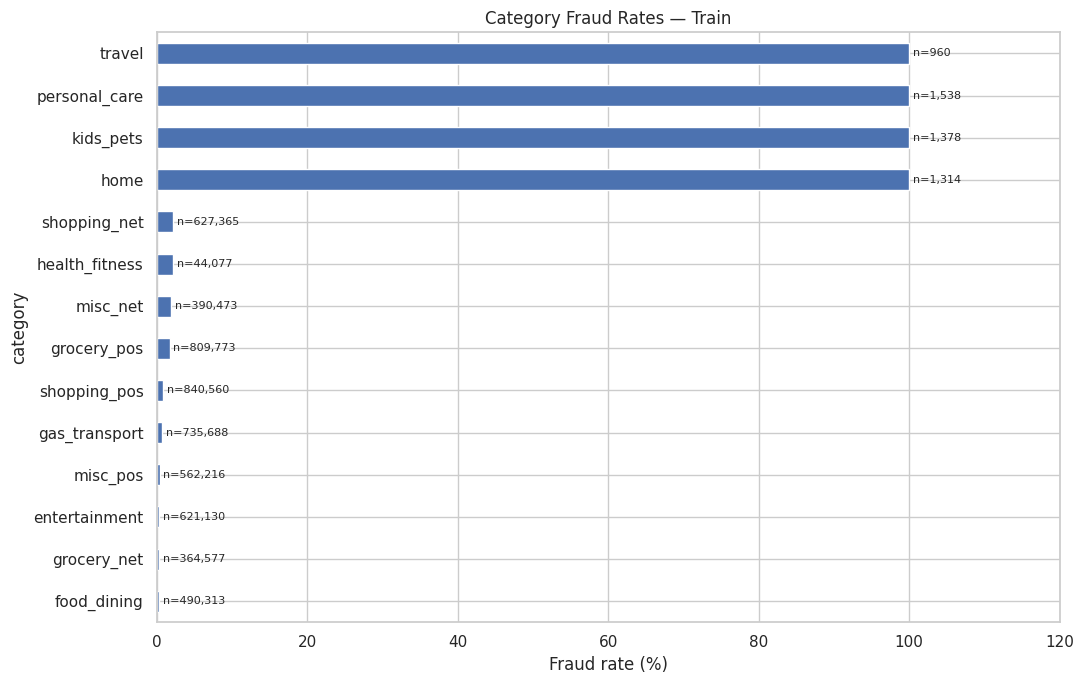

In [ ]:
category_plot = category_train.sort_values('fraud_pct')
ax = category_plot['fraud_pct'].plot(kind='barh', figsize=(11, 7))
for i, (_, row) in enumerate(category_plot.iterrows()):
    ax.text(row['fraud_pct'] + 0.5, i, f"n={int(row['n']):,}", va='center', fontsize=8)
plt.xlim(0, 120); plt.xlabel('Fraud rate (%)')
plt.title('Category Fraud Rates — Train'); plt.tight_layout(); plt.show()


**Fraud rate by category**

- Four categories (`home`, `kids_pets`, `personal_care`, and `travel`) contain only fraudulent transactions in the training partition. This is an unusual pattern and may indicate a dataset-generation artifact; it should not be interpreted as a universal rule about these categories.
- Other relatively high observed rates include `shopping_net` (2.19%), `health_fitness` (2.11%), `misc_net` (1.91%), and `grocery_pos` (1.67%).
- The category association is strong in the training data (Cramér's V ≈ 0.31). Because some categories have no legitimate training examples and category composition changes over time, `category` is excluded from model inputs to reduce reliance on potentially unstable shortcuts.

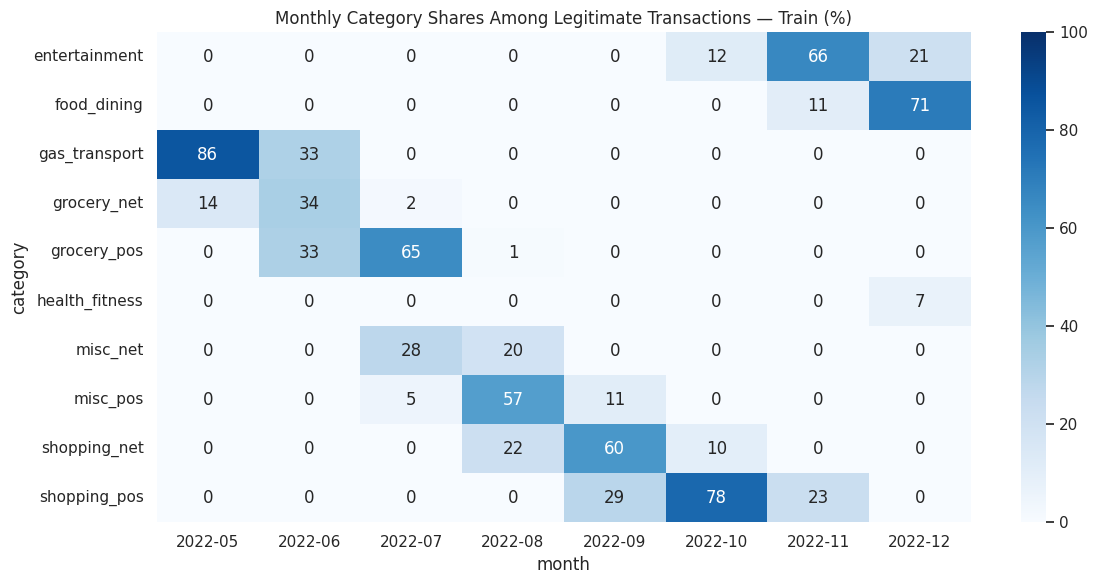

In [ ]:
daily = train.groupby(['trans_date', 'category', 'is_fraud'], observed=True).size().rename('n').reset_index()
daily['month'] = daily['trans_date'].str[:7]
legitimate = daily[daily['is_fraud'].eq(0)]
monthly = legitimate.pivot_table(index='category', columns='month', values='n', aggfunc='sum', fill_value=0, observed=True)
share = monthly.div(monthly.sum(axis=0), axis=1) * 100
plt.figure(figsize=(12, 6)); sns.heatmap(share, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100)
plt.title('Monthly Category Shares Among Legitimate Transactions — Train (%)')
plt.tight_layout(); plt.show()


**Monthly category heatmap (legitimate transactions only)**

The category mix among legitimate transactions changes substantially across the training months. For example, `gas_transport` accounts for a large share of legitimate transactions in May but little or none in some later months; other categories dominate different months. This instability suggests that category–calendar combinations may act as shortcuts in random splits and may not generalize to later periods. The protocol ablation in Section 2.8 examines this concern. These observations support a cautious decision to exclude category and calendar features from the final model specification.

**Feature policy:** Category is excluded because four categories have no legitimate examples in the training partition and the category mix changes substantially over time. The protocol ablation in Section 2.8 also examines how category and calendar features behave under random versus chronological splits. Large positive transaction amounts are retained; their currency and the dataset-generation rules remain unconfirmed.


## 1.6 Customer-History Columns — Train
Inspect all three count fields and three average-amount fields directly on train.


In [ ]:
customer_history = dictionary.loc[dictionary['group'].eq('Customer history'), 'column'].tolist()
display(numeric.loc[customer_history, ['count', 'mean', 'std', 'min', '50%', 'max']])
train.groupby('is_fraud', observed=True)[customer_history].median().T


,count,mean,std,min,50%,max
customer_num_trans_1_day,5491362.0,2.999704,1.999959,0.0,3.0,6.0
customer_num_trans_7_day,5491362.0,5.499843,2.629254,0.0,6.0,11.0
customer_num_trans_30_day,5491362.0,13.000065,3.135072,5.0,13.0,21.0
customer_avg_amout_1_day,5491362.0,45.488483,25.689336,1.0,45.48,90.0
customer_avg_amount_7_day,5491362.0,45.50758,25.696692,1.0,45.52,90.0
customer_avg_amount_30_day,5491362.0,35.509511,19.920732,1.0,35.51,70.0


is_fraud,0,1
customer_num_trans_1_day,3.0,3.0
customer_num_trans_7_day,6.0,6.0
customer_num_trans_30_day,13.0,13.0
customer_avg_amout_1_day,45.48,45.19
customer_avg_amount_7_day,45.52,45.58
customer_avg_amount_30_day,35.51,35.61


**Supplied customer-history columns:** The class-wise medians are similar for the reported transaction-count windows (3/6/13) and average-amount fields (approximately 45–46). Some values are bounded and appear close to uniform, while the source definitions and point-in-time construction are unverified. These checks do not prove that the fields are random, but they are insufficient to establish that the fields are reliable historical summaries. The model therefore excludes them and uses independently derived card-history features instead.

## 1.7 Merchant-History Columns — Train
Inspect all three transaction fields and four risk fields. Fractional values/order checks above are reported without inventing source definitions.


In [ ]:
merchant_history = dictionary.loc[dictionary['group'].eq('Merchant history'), 'column'].tolist()
display(numeric.loc[merchant_history, ['count', 'mean', 'std', 'min', '50%', 'max']])
train.groupby('is_fraud', observed=True)[merchant_history].median().T


,count,mean,std,min,50%,max
merchant_num_trans_1_day,5491362.0,2549.261087,1414.689555,100.0,2548.64,5000.0
merchant_num_trans_7_day,5491362.0,50481.827083,28580.184492,1000.0,50477.23,99999.98
merchant_num_trans_30_day,5491362.0,554983.313352,314653.258465,10000.11,555152.89,1099999.48
merchant_risk_1_day,5491362.0,3.499658,2.291259,0.0,3.0,7.0
merchant_risk_7_day,5491362.0,9.252172,3.832102,0.0,9.0,15.0
merchant_risk_30_day,5491362.0,16.127334,4.789924,0.0,17.0,23.0
merchant_risk_90_day,5491362.0,29.626726,12.248379,0.0,30.0,50.0


is_fraud,0,1
merchant_num_trans_1_day,2548.8,2535.21
merchant_num_trans_7_day,50478.98,50330.81
merchant_num_trans_30_day,555130.17,557590.35
merchant_risk_1_day,3.0,4.0
merchant_risk_7_day,9.0,9.0
merchant_risk_30_day,17.0,17.0
merchant_risk_90_day,30.0,30.0


**Supplied merchant-history columns:** `merchant_num_trans_1_day` spans approximately 100–5,000, with a median around 2,549 in both classes; several risk fields also have similar class-wise medians. Together with the fractional values and window-ordering violations identified earlier, these patterns make the intended meaning and reliability of these fields unclear. They are excluded from model inputs unless their source definitions can be verified.

## 1.8 Associations and Variable Review — Train
Use the same training sample for computationally expensive Spearman correlations, including all original numeric columns plus derived age and distance. This plot is explicitly sample-based.


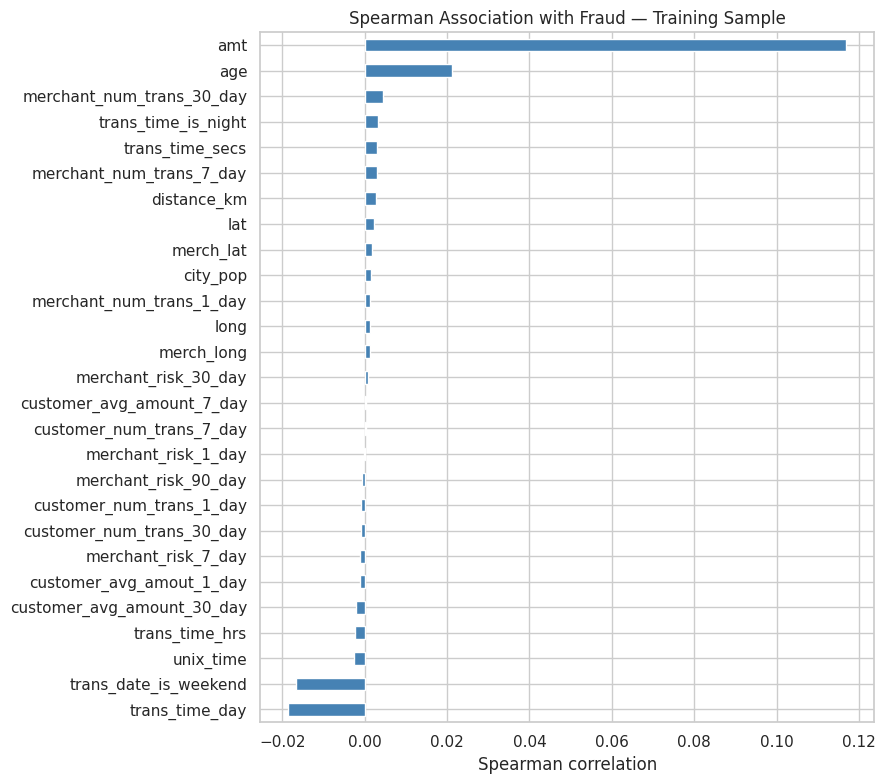

In [ ]:
correlation_columns = numeric_columns + ['age', 'distance_km']
correlations = data[correlation_columns].corr(method='spearman')['is_fraud'].drop('is_fraud')
correlations.sort_values().plot(kind='barh', figsize=(9, 8), color='steelblue')
plt.title('Spearman Association with Fraud — Training Sample')
plt.xlabel('Spearman correlation'); plt.tight_layout(); plt.show()


**Spearman association with fraud**

- `amt` has the largest displayed monotonic association (approximately 0.117), followed by age (approximately 0.02); most other coefficients have absolute magnitude below 0.02.
- Spearman correlation captures monotonic association, not all nonlinear, threshold, or cyclical relationships. For example, a weak correlation for a time variable does not rule out useful hour-specific patterns.
- This plot is exploratory and should not be used alone to discard features. Feature choices also consider source reliability, temporal availability, model evaluation, and the risk of leakage.

In [ ]:
dictionary[['column', 'group', 'unique', 'missing_pct']]


,column,group,unique,missing_pct
0,ssn,Identifiers,9460,0.0
1,cc_num,Identifiers,9460,0.0
2,first,Identifiers,660,0.0
3,last,Identifiers,984,0.0
4,gender,Customer,2,0.0
5,street,Identifiers,9460,0.0
6,city,Customer,3585,0.0
7,state,Customer,51,0.0
8,zip,Identifiers,6572,0.0
9,lat,Customer,6434,0.0


## 1.9 Hypothesis Tests — Train
Retain the two chi-square tests, Holm correction and Cramér's V. Use all training transactions. Transactions repeat within customers, so p-values are exploratory and rely on an imperfect independence assumption.


In [ ]:
test_rows = []
for column in ['gender', 'category']:
    table = pd.crosstab(train[column], train['is_fraud'])
    chi2, p, dof, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * min(table.shape[0]-1, table.shape[1]-1)))
    test_rows.append([column, len(train), chi2, dof, p, v, expected.min(), (expected < 5).sum()])
tests = pd.DataFrame(test_rows, columns=['variable', 'n', 'chi2', 'dof', 'p_raw', 'cramers_v', 'min_expected', 'expected_cells_lt5'])


In [ ]:
order = tests['p_raw'].sort_values().index
adjusted = np.maximum.accumulate(tests.loc[order, 'p_raw'].to_numpy() * np.arange(len(tests), 0, -1))
tests.loc[order, 'p_holm'] = np.minimum(adjusted, 1)
tests['reject_at_0.05_nominal'] = tests['p_holm'] < 0.05
tests


,variable,n,chi2,dof,p_raw,cramers_v,min_expected,expected_cells_lt5,p_holm,reject_at_0.05_nominal
0,gender,5491362,15.613013,1,0.000078,0.001686,28962.278811,0,0.000078,True
1,category,5491362,512650.157551,13,0.000000,0.305542,10.158616,0,0.000000,True


**Chi-square tests with Holm correction**

- `category` has a strong association with fraud in the training partition (χ² ≈ 512,650; Cramér's V ≈ 0.306). The association between `gender` and fraud is much smaller (V ≈ 0.0017), despite a small adjusted p-value.
- With more than 5 million observations, small differences can be statistically significant. Effect sizes are therefore important for interpretation.
- Transactions repeat within customers, so the independence assumption is imperfect. Treat these tests as exploratory evidence rather than definitive inferential conclusions.

> **Why this EDA matters:** every chart, sanity check and statistical test above uses the training period only. This keeps the analysis honest: patterns discovered here are used to guide feature decisions, not to peek at future performance.


## 1.10 Features and Preprocessing
Features are built from deterministic formulas; medians, scaler and the state vocabulary are fitted on train only. Besides the transaction features (log amount, age, customer–merchant distance, log city population, cyclic hour and weekday, state one-hot), the model uses **card-history features** derived from `cc_num` and earlier timestamps (Section 1.10b). Raw history columns, raw identifiers, gender and category are not model inputs.

After EDA finishes, load only the selected modelling fields for held-out rows. Deterministic transformations may be applied to validation/test; they do not learn from held-out distributions. No held-out labels are summarized or used to choose transformations.


In [ ]:
feature_review = dictionary[['column', 'group', 'description']].copy()
feature_review['default_model_use'] = 'Excluded; retained in train EDA'
usage = {'amt': 'log_amount only', 'dob': 'age at transaction', 'city_pop': 'log_city_pop', 'state': 'training-vocabulary one-hot',
         'lat': 'distance_km', 'long': 'distance_km', 'merch_lat': 'distance_km', 'merch_long': 'distance_km',
         'trans_date': 'split, age and weekday', 'trans_time': 'split and cyclic hour', 'is_fraud': 'Target only',
         'cc_num': 'card-history features only (not a raw feature)'}
feature_review['default_model_use'] = feature_review['column'].map(usage).fillna(feature_review['default_model_use'])
feature_review


,column,group,description,default_model_use
0,ssn,Identifiers,Customer identifier; exact semantics unverified,Excluded; retained in train EDA
1,cc_num,Identifiers,Payment card identifier; preserve precision,card-history features only (not a raw feature)
2,first,Identifiers,Given name,Excluded; retained in train EDA
3,last,Identifiers,Family name,Excluded; retained in train EDA
4,gender,Customer,Recorded gender; source definitions unverified,Excluded; retained in train EDA
5,street,Identifiers,Street address,Excluded; retained in train EDA
6,city,Customer,Customer city,Excluded; retained in train EDA
7,state,Customer,Recorded state/region,training-vocabulary one-hot
8,zip,Identifiers,Postal code; raw leading zeros may already be ...,Excluded; retained in train EDA
9,lat,Customer,"Customer latitude, interpreted from column name",distance_km


In [ ]:
model_source_columns = ['trans_date', 'trans_time', 'cc_num', 'dob', 'amt', 'city_pop', 'gender', 'state', 'category',
                        'lat', 'long', 'merch_lat', 'merch_long', 'is_fraud']
train_model = train[model_source_columns].copy()
train_model['source_row'] = train.index.to_numpy(dtype='int32')
train_model['datetime'] = train['datetime'].to_numpy()
dictionary.to_csv(results_dir / 'train_dictionary.csv', index=False)
numeric.to_csv(results_dir / 'train_numeric_summary.csv')
profile.to_csv(results_dir / 'train_column_profile.csv')
del train, data, event, birth, seconds, night, epoch, before_birthday, lat1, lat2, dlat, dlon, a
gc.collect()


16464

In [ ]:
heldout_parts, offset = [], 0
for chunk in pd.read_csv(csv_path, usecols=model_source_columns, dtype={'cc_num': 'string[pyarrow]'},
                         dtype_backend='pyarrow', chunksize=CHUNK_SIZE):
    row_ids = np.arange(offset, offset + len(chunk), dtype='int32')
    keep = split_by_row[row_ids] != 0
    part = chunk.loc[keep].copy()
    part['source_row'] = row_ids[keep]
    heldout_parts.append(part)
    offset += len(chunk)
heldout = pd.concat(heldout_parts, ignore_index=True)
heldout['datetime'] = pd.to_datetime(heldout.pop('trans_date') + ' ' + heldout.pop('trans_time'))
del heldout_parts, chunk, part, row_ids, keep
gc.collect()


2950

In [ ]:
train_model = train_model.drop(columns=['trans_date', 'trans_time'])
transactions = pd.concat([train_model, heldout], ignore_index=True)
transactions['cc_num'] = transactions['cc_num'].astype('string')   # one consistent dtype across train and held-out rows
transactions['dob'] = pd.to_datetime(transactions['dob'])
transactions['is_fraud'] = transactions['is_fraud'].astype('int8')
transactions[['gender', 'state', 'category']] = transactions[['gender', 'state', 'category']].astype('category')
transactions = transactions.sort_values(['datetime', 'source_row']).reset_index(drop=True)
times = transactions['datetime']
assert np.array_equal(transactions['source_row'].to_numpy(), timeline['source_row'].to_numpy())
del train_model, heldout, timeline, split_by_row, train_row_ids
gc.collect()


0

In [ ]:
birth = transactions['dob']
before_birthday = ((times.dt.month < birth.dt.month) |
                   ((times.dt.month == birth.dt.month) & (times.dt.day < birth.dt.day)))
transactions['age'] = (times.dt.year - birth.dt.year - before_birthday.astype(int)).astype('float32')
transactions['log_amount'] = np.log1p(transactions['amt'].clip(lower=0)).astype('float32')
transactions['log_city_pop'] = np.log1p(transactions['city_pop'].clip(lower=0)).astype('float32')
hour = times.dt.hour + times.dt.minute / 60 + times.dt.second / 3600
weekday = times.dt.dayofweek
transactions['hour_sin'] = np.sin(2 * np.pi * hour / 24).astype('float32')
transactions['hour_cos'] = np.cos(2 * np.pi * hour / 24).astype('float32')
transactions['weekday_sin'] = np.sin(2 * np.pi * weekday / 7).astype('float32')
transactions['weekday_cos'] = np.cos(2 * np.pi * weekday / 7).astype('float32')

In [ ]:
lat1, lat2 = np.radians(transactions['lat']), np.radians(transactions['merch_lat'])
dlat = lat2 - lat1
dlon = np.radians(transactions['merch_long'] - transactions['long'])
a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
transactions['distance_km'] = (6371.0088 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))).astype('float32')
del lat1, lat2, dlat, dlon, a, birth, before_birthday


### 1.10b Point-in-Time Card-History Features

These features describe each card's recent behaviour using only transactions with a **strictly earlier timestamp** on the same card (rows with the same timestamp are never used), so they are available at scoring time:

- `card_is_first_tx` — 1 if the card has no earlier transaction in the data.
- `log_hours_since_prev` — `log1p` of the hours since the previous transaction (0 for a first transaction, flagged above).
- `card_tx_count_24h` — number of the card's transactions in the 24 hours before the current one.
- `card_log_amt_ratio_prev` — `log1p(amt) − log1p(previous amt)`; a symmetric, bounded version of the amount ratio.

History is computed over the whole chronological timeline, so the first held-out transactions of a card correctly see that card's earlier training-period activity. Missing history is encoded with an explicit flag instead of a sentinel value, so it does not distort the scaler.


In [ ]:
CARD_HISTORY_FEATURES = ['card_is_first_tx', 'log_hours_since_prev', 'card_tx_count_24h', 'card_log_amt_ratio_prev']

def add_card_history(df):
    """Point-in-time card history using only STRICTLY EARLIER timestamps of the same card.
    Fully vectorised; keeps the row order of `df` unchanged."""
    codes, _ = pd.factorize(df['cc_num'].astype('string'))
    assert (codes >= 0).all(), 'cc_num must not contain missing values'
    secs = (df['datetime'] - df['datetime'].min()).dt.total_seconds().to_numpy().astype('int64')
    amt = df['amt'].to_numpy('float64').clip(min=0)
    order = np.lexsort((df['source_row'].to_numpy(), secs, codes))   # card, then time, then source_row
    c, t, a = codes[order].astype('int64'), secs[order], amt[order]
    day = 24 * 3600
    stride = int(t.max()) + 2 * day + 1                               # keeps different cards' key ranges disjoint
    key = c * stride + t
    right = np.searchsorted(key, key, side='left')                    # rows strictly earlier in time are < right
    left = np.searchsorted(key, key - day, side='left')               # first row inside [t - 24h, t)
    count = (right - left).astype('float32')
    prev = right - 1
    has_prev = (prev >= 0) & (c[np.maximum(prev, 0)] == c)
    p = np.where(has_prev, prev, 0)
    hours = np.where(has_prev, (t - t[p]) / 3600.0, 0.0)
    log_ratio = np.where(has_prev, np.log1p(a) - np.log1p(a[p]), 0.0)
    values = {'card_is_first_tx': (~has_prev).astype('float32'),
              'log_hours_since_prev': np.log1p(hours).astype('float32'),
              'card_tx_count_24h': count,
              'card_log_amt_ratio_prev': log_ratio.astype('float32')}
    out = df.copy()
    for name, v in values.items():
        col = np.empty(len(df), dtype='float32'); col[order] = v
        out[name] = col
    return out


In [ ]:
transactions = add_card_history(transactions)
transactions = transactions.drop(columns=['cc_num'])
times = transactions['datetime']          # row order is unchanged; refresh the alias anyway
assert times.is_monotonic_increasing
print('Card-history features added:', CARD_HISTORY_FEATURES)
display(transactions[CARD_HISTORY_FEATURES].describe().round(3))


Card-history features added: ['card_is_first_tx', 'log_hours_since_prev', 'card_tx_count_24h', 'card_log_amt_ratio_prev']


,card_is_first_tx,log_hours_since_prev,card_tx_count_24h,card_log_amt_ratio_prev
count,8580255.000,8580255.000,8580255.000,8580255.000
mean,0.001,1.611,3.986,-0.000
std,0.034,1.132,3.163,1.750
min,0.000,0.000,0.000,-8.955
25%,0.000,0.650,2.000,-1.081
50%,0.000,1.317,3.000,0.000
75%,0.000,2.773,6.000,1.083
max,1.000,5.967,38.000,9.163


**Check:** all four features must be finite; `card_is_first_tx` should be 1 only for a small share of rows (each card's first appearance).


is_fraud,legitimate (mean),fraud (mean)
card_is_first_tx,0.002,0.014
log_hours_since_prev,1.585,1.190
card_tx_count_24h,4.046,3.659
card_log_amt_ratio_prev,-0.003,0.215


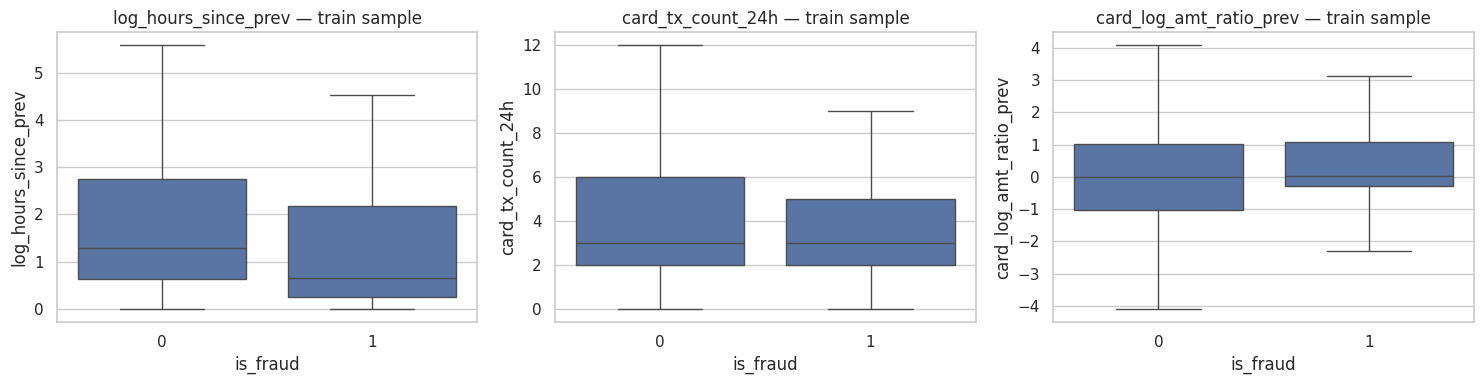

In [ ]:
# Train-only look at the new features by class (justifies using them; no validation/test labels involved).
hist_train = transactions.iloc[:validation_start]
hist_sample = hist_train[CARD_HISTORY_FEATURES + ['is_fraud']].sample(n=min(200_000, len(hist_train)), random_state=SEED)
display(hist_train.groupby('is_fraud')[CARD_HISTORY_FEATURES].mean().T.rename(columns={0: 'legitimate (mean)', 1: 'fraud (mean)'}).round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['log_hours_since_prev', 'card_tx_count_24h', 'card_log_amt_ratio_prev']):
    sns.boxplot(data=hist_sample, x='is_fraud', y=col, showfliers=False, ax=ax)
    ax.set_title(col + ' — train sample')
plt.tight_layout(); plt.show()
del hist_train, hist_sample; _ = gc.collect()


**Point-in-time card-history features (training data)**

- Fraudulent transactions have a shorter average interval since the previous transaction (mean `log_hours_since_prev` 1.19 versus 1.59) and a slightly lower mean 24-hour transaction count (3.66 versus 4.05). The mean `card_log_amt_ratio_prev` is also higher for fraud (+0.215 versus −0.003).
- The distributions overlap substantially, so these variables should not be treated as reliable stand-alone rules. Their value may come from interactions with transaction amount and time.
- `card_is_first_tx` is associated with a higher observed fraud rate but applies to only a small fraction of rows.
- The features use only strictly earlier transactions and no labels. This avoids using same-time or future transactions when constructing the history, although source-data quality and other feature definitions still require scrutiny.

In [ ]:
numeric_features = ['log_amount', 'age', 'distance_km', 'log_city_pop', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', *CARD_HISTORY_FEATURES]
train_numeric = transactions.iloc[:validation_start][numeric_features]
assert np.isfinite(train_numeric.to_numpy()).all()
medians = train_numeric.median()
scaler = StandardScaler().fit(train_numeric.fillna(medians))
state_levels = sorted(transactions.iloc[:validation_start]['state'].dropna().astype(str).unique().tolist())


In [ ]:
source_hash = hashlib.sha256()
with open(csv_path, 'rb') as file:
    for block in iter(lambda: file.read(8*1024*1024), b''):
        source_hash.update(block)
input_manifest = {'source': 'data.csv', 'source_sha256': source_hash.hexdigest(), 'rows': n, 'columns': len(raw_columns)}


In [ ]:
state_columns = ['state_' + value for value in state_levels]
feature_columns = numeric_features + state_columns
settings = {'version': 'train_only_v4', 'numeric_features': numeric_features, 'state_levels': state_levels,
            'columns': feature_columns, 'medians': medians, 'scaler': scaler, 'dtype': 'float32',
            'target': 'is_fraud', 'slices': slices, 'source_sha256': input_manifest['source_sha256'],
            'versions': {'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__}}


In [ ]:
settings['feature_rules'] = {'age': 'completed years at datetime', 'distance': 'Haversine radius 6371.0088 km',
    'amount': 'log1p(amt), omit raw amt', 'population': 'log1p(city_pop)',
    'hour': 'sin/cos of fractional source-clock hour, period 24', 'weekday': 'sin/cos of Monday=0, period 7',
    'state': 'training vocabulary; unseen => all zero',
    'card_history': 'strictly earlier timestamps of the same card; first transaction flagged, no sentinel values', 'clock': 'source trans_date + trans_time; timezone unknown'}
settings['excluded'] = ['category', 'gender', 'raw identifiers (cc_num only builds card-history features)', 'raw history fields', 'profile', 'supplied derived clock fields']
settings['eda_scope'] = 'train_only'
settings['cutoffs'] = {'validation_start': str(times.iloc[validation_start]), 'test_start': str(times.iloc[test_start])}
settings['split_policy'] = 'chronological ~64/16/20; whole timestamps; stable source_row tie-break'
_ = joblib.dump(settings, output / 'preprocessing_settings.joblib')


Median filling is a fallback; current training completeness is shown above. Keep large positive amounts. All prepared model features are float32. Vocabulary and scaling are fitted on train only; unseen states map to all-zero state columns.


In [ ]:
for name, (start, end) in slices.items():
    frame = transactions.iloc[start:end]
    X = pd.DataFrame(scaler.transform(frame[numeric_features].fillna(medians)), columns=numeric_features)
    state = pd.Categorical(frame['state'], categories=state_levels)
    encoded = pd.get_dummies(state, prefix='state', dtype='float32').reindex(columns=state_columns, fill_value=0)
    X = pd.concat([X, encoded], axis=1).astype('float32')
    assert X.columns.tolist() == feature_columns and np.isfinite(X.to_numpy()).all()
    X['is_fraud'] = frame['is_fraud'].to_numpy(dtype='int8')
    X.to_parquet(output / (name + '_ready.parquet'), index=False)
    print(name, X.shape, "| feature dtype: float32")
    del X, encoded, state
    gc.collect()


train (5491362, 64) | feature dtype: float32
validation (1372841, 64) | feature dtype: float32
test (1716052, 64) | feature dtype: float32


In [ ]:
for name, (start, end) in slices.items():
    transactions.iloc[start:end][['source_row', 'datetime', 'amt', 'is_fraud', 'category']].to_parquet(
        output / (name + '_row_index.parquet'), index=False)

cv_source_cols = numeric_features + ['state', 'datetime', 'is_fraud']
transactions.iloc[:validation_start][cv_source_cols].tail(min(N_CV, validation_start)).to_parquet(
    output / 'train_cv_source.parquet', index=False)
print('Saved row indices and fold-isolated CV source; row indices are never model features.')

Saved row indices and fold-isolated CV source; row indices are never model features.


## 1.11 Handoff Checks
Verify prepared row counts and feature order without computing held-out class distributions. These structural checks are not EDA or model selection. Row-index files are never model features.


In [ ]:
checks = []
for name, (start, end) in slices.items():
    schema = pq.read_schema(output / (name + '_ready.parquet'))
    rows_saved = pq.ParquetFile(output / (name + '_ready.parquet')).metadata.num_rows
    assert schema.names == feature_columns + ['is_fraud'] and rows_saved == end - start
    assert all(str(schema.field(c).type) == 'float' for c in feature_columns)
    checks.append({'split': name, 'rows': rows_saved, 'features': len(feature_columns), 'float32': True})


In [ ]:
# check exist output file
output.mkdir(parents=True, exist_ok=True)

# check if file not write, write again
try:
    for name, (start, end) in slices.items():
        file_path = output / f'{name}_ready.parquet'
        if not file_path.exists():
            print(f"File {file_path.name} is missing. Re-saving from transactions variable...")
            frame = transactions.iloc[start:end]
            X = pd.DataFrame(scaler.transform(frame[numeric_features].fillna(medians)), columns=numeric_features)
            state = pd.Categorical(frame['state'], categories=state_levels)
            encoded = pd.get_dummies(state, prefix='state', dtype='float32').reindex(columns=state_columns, fill_value=0)
            X = pd.concat([X, encoded], axis=1).astype('float32')
            X['is_fraud'] = frame['is_fraud'].to_numpy(dtype='int8')
            X.to_parquet(file_path, index=False)
            print(f"Successfully saved {file_path.name}")
except NameError as e:
    print(f"Variable missing: {e}. Please ensure Section 1.10 has been run sequentially first.")


In [ ]:
with open(output / 'validation_checks.json', 'w') as file:
    json.dump({'passed': True, 'rows_retained': n, 'source_row_unique': True, 'strict_time_boundaries': True,
               'train_only_fit': True, 'checks': checks}, file, indent=2)
print(pd.DataFrame(checks).to_string(index=False))


     split    rows  features  float32
     train 5491362        63     True
validation 1372841        63     True
      test 1716052        63     True


**Preprocessing handoff:** The prepared data contain **63 model features** (12 numerical/derived features and 51 one-hot state indicators), stored as `float32`. The train, validation, and test partitions contain 5,491,362, 1,372,841, and 1,716,052 rows, respectively. The scaler, fallback medians, and state vocabulary are fitted on training data and reused for held-out partitions; unseen states map to all-zero state indicators. Automated assertions check row counts and feature consistency.

In [ ]:
tables = {'train_category_rates': category_train, 'train_amount_by_label': amount_by_label,
          'train_chi_square': tests, 'train_hour_rates': hour_stats_train,
          'train_feature_review': feature_review, 'train_time_checks': time_checks,
          'train_numeric_checks': numeric_checks, 'train_fractional_counts': fractional}
for name, table in tables.items():
    table.to_csv(results_dir / (name + '.csv'))
with open(output / 'feature_schema.json', 'w') as file:
    json.dump({'features': feature_columns, 'dtype': 'float32', 'target': 'is_fraud', 'target_dtype': 'int8',
               'rules': settings['feature_rules'], 'versions': settings['versions'], 'eda_scope': 'train_only'}, file, indent=2)


In [ ]:
# Ghi đè lại các file parquet bị lệch cấu trúc để đồng bộ với RAM
for name, (start, end) in slices.items():
    frame = transactions.iloc[start:end]
    X = pd.DataFrame(scaler.transform(frame[numeric_features].fillna(medians)), columns=numeric_features)
    state = pd.Categorical(frame['state'], categories=state_levels)
    encoded = pd.get_dummies(state, prefix='state', dtype='float32').reindex(columns=state_columns, fill_value=0)
    X = pd.concat([X, encoded], axis=1).astype('float32')
    X['is_fraud'] = frame['is_fraud'].to_numpy(dtype='int8')
    X.to_parquet(output / (name + '_ready.parquet'), index=False)
    print(f"Re-saved {name} with shape {X.shape}")
    del X, encoded, state
    gc.collect()

# Đọc và xác nhận lại cấu trúc file
schema = pq.read_schema(output / 'train_ready.parquet')
actual_features = [c for c in schema.names if c != 'is_fraud']

assert actual_features == feature_columns
assert scaler.n_samples_seen_ == validation_start
print('Training rows used to fit preprocessing:', scaler.n_samples_seen_)
print('Shared model features:', len(feature_columns))
del transactions, train_numeric, times, frame
gc.collect()

Validation successful!
Training rows used to fit scaler: 5491362
Actual features count in Parquet file: 63
Expected features count in RAM settings: 63


74

> **Preprocessing controls:** Median values, scaling statistics, and the state vocabulary are fitted on training rows and then reused for validation and test. Card-history features are constructed from strictly earlier transactions for the same card. These choices reduce leakage risk, but they do not guarantee that every source field is point-in-time valid or free from data-quality issues.

# 2. Build the Models

Five models are compared: a logistic baseline (SGD, log-loss), Gaussian Naive Bayes, a linear SVM (SGD, hinge loss), LightGBM, and a Decision Tree / Random Forest candidate selected by temporal cross-validation. Matrices are already standardised; they are not scaled again. Class imbalance is handled inside the models (class weights / negative bagging), never by changing the evaluation data.

`PR-AUC` is average precision (`sklearn.metrics.average_precision_score`).

In [ ]:
OUT = output   # folder with the prepared parquet files from Part 1
assert (OUT / 'feature_schema.json').is_file(), 'Run Part 1 first: feature_schema.json is missing.'
FEATURES = json.load(open(OUT / 'feature_schema.json'))['features']
RESULTS, PROBS, SCORERS = {}, {}, {}

def load(split):
    df = pd.read_parquet(OUT / f'{split}_ready.parquet')
    y = df.pop('is_fraud').to_numpy(np.int8)
    assert df.columns.tolist() == FEATURES
    X = df.to_numpy(np.float32)
    del df; _ = gc.collect()
    return X, y

def evaluate(name, y, p, thr=None, verbose=True):
    """PR-AUC / ROC-AUC are threshold-free. If thr is None the F1-optimal threshold is chosen (validation only)."""
    prec, rec, ths = precision_recall_curve(y, p)
    ap = average_precision_score(y, p)
    if thr is None:
        f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
        thr = ths[f1s.argmax()]
    pred = p >= thr
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum()); fn = int((~pred & (y == 1)).sum())
    tn = len(y) - tp - fp - fn
    pr, rc = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    f1, roc = 2 * pr * rc / max(pr + rc, 1e-12), roc_auc_score(y, p)
    RESULTS[name] = {'PR-AUC': ap, 'ROC-AUC': roc, 'Precision': pr, 'Recall': rc, 'F1': f1,
                     'Threshold': thr, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}
    if verbose:
        print(f"\n{'=' * 10} {name} {'=' * 10}")
        print(f'ROC-AUC {roc:.4f} | PR-AUC {ap:.4f} | threshold {thr:.4f}')
        print(f'Precision {pr:.4f} | Recall {rc:.4f} | F1 {f1:.4f}')
        print(f"{'':<16}{'Pred: legit':>14}{'Pred: fraud':>14}")
        print(f"{'Actual: legit':<16}{tn:>14,}{fp:>14,}")
        print(f"{'Actual: fraud':<16}{fn:>14,}{tp:>14,}")
        print(f'=> caught {tp:,}/{tp + fn:,} frauds ({rc:.1%}) with {fp:,} false alarms among {tn + fp:,} legitimate transactions ({fp / max(tn + fp, 1):.2%}).')
    return thr, ap

X_tr, y_tr = load('train')
X_va, y_va = load('validation')
overview = pd.DataFrame({'Rows': [len(y_tr), len(y_va)], 'Fraud': [int(y_tr.sum()), int(y_va.sum())],
                         'Fraud rate (%)': [y_tr.mean() * 100, y_va.mean() * 100], 'Features': [X_tr.shape[1]] * 2},
                        index=['Train', 'Validation'])
display(overview.style.format({'Rows': '{:,}', 'Fraud': '{:,}', 'Fraud rate (%)': '{:.2f}'}))

,Rows,Fraud,Fraud rate (%),Features
Train,"5,491,362","58,109",1.06,63
Validation,"1,372,841","15,747",1.15,63


**Train/validation overview:**

Train has 58,109 frauds (1.06%) and validation 15,747 (1.15%), both large enough for stable estimates. The fraud rate drifts up slightly over time, so a threshold chosen on validation may be slightly off on test (see Section 4.1).

## 2.1 SGD Logistic Baseline

In [ ]:
t0 = time.time()
lr = SGDClassifier(loss='log_loss', alpha=1e-4, class_weight='balanced', max_iter=SGD_MAX_ITER, tol=1e-3, random_state=SEED).fit(X_tr, y_tr)
print(f'Training time: {time.time() - t0:.1f}s')
SCORERS['Logistic (SGD)'] = lambda X: lr.predict_proba(X)[:, 1]
PROBS['Logistic (SGD)'] = SCORERS['Logistic (SGD)'](X_va)
thr_lr, _ = evaluate('Logistic (SGD) · Validation', y_va, PROBS['Logistic (SGD)'])

Training time: 68.9s

========== Logistic (SGD) · Validation ==========
ROC-AUC 0.9219 | PR-AUC 0.5461 | threshold 0.9372
Precision 0.7452 | Recall 0.4579 | F1 0.5673
                   Pred: legit   Pred: fraud
Actual: legit        1,354,628         2,466
Actual: fraud            8,536         7,211
=> caught 7,211/15,747 frauds (45.8%) with 2,466 false alarms among 1,357,094 legitimate transactions (0.18%).


**Logistic (SGD), the baseline**
- ROC-AUC 0.922 but PR-AUC only **0.546**; at the F1-optimal threshold: precision 74.5%, recall **45.8%**, i.e. 8,536 of 15,747 frauds missed. FP = 2,466 (0.18% of legitimate).
- High ROC-AUC with low PR-AUC is typical for imbalanced data: ROC-AUC is inflated by the huge legitimate class. PR-AUC is the right metric.
- Limitation: a linear model cannot capture non-linear structure (two-peaked amounts, step-shaped hours). The very high threshold (0.937) results from `class_weight='balanced'` inflating probabilities, so probabilities are uncalibrated.
- Fine as a baseline (~63 s training).

## 2.2 LightGBM

Average precision on validation drives early stopping. Negative bagging (`neg_bagging_fraction=0.2`) handles the imbalance.

In [ ]:
DS = {'max_bin': 63, 'feature_pre_filter': False}
params = dict(objective='binary', metric='average_precision', learning_rate=0.1, num_leaves=63,
              min_data_in_leaf=200, feature_fraction=0.8, bagging_freq=1, neg_bagging_fraction=0.2,
              max_bin=63, force_row_wise=True, num_threads=0, verbose=-1, seed=SEED)

dtrain = lgb.Dataset(X_tr, y_tr, feature_name=FEATURES, params=DS).construct()
dval = lgb.Dataset(X_va, y_va, reference=dtrain, params=DS)
booster = lgb.train(params, dtrain, 500, valid_sets=[dval],
                    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(50)])

SCORERS['LightGBM'] = lambda X: booster.predict(X, num_iteration=booster.best_iteration)
PROBS['LightGBM'] = SCORERS['LightGBM'](X_va)
thr_gb, _ = evaluate('LightGBM · Validation', y_va, PROBS['LightGBM'])

[50]	valid_0's average_precision: 0.88957
[100]	valid_0's average_precision: 0.90255
[150]	valid_0's average_precision: 0.905094
[200]	valid_0's average_precision: 0.905902
[250]	valid_0's average_precision: 0.90673
[300]	valid_0's average_precision: 0.907989
[350]	valid_0's average_precision: 0.909974
[400]	valid_0's average_precision: 0.909998
[450]	valid_0's average_precision: 0.911067
[500]	valid_0's average_precision: 0.91164

========== LightGBM · Validation ==========
ROC-AUC 0.9973 | PR-AUC 0.9120 | threshold 0.7234
Precision 0.8494 | Recall 0.8388 | F1 0.8441
                   Pred: legit   Pred: fraud
Actual: legit        1,354,753         2,341
Actual: fraud            2,539        13,208
=> caught 13,208/15,747 frauds (83.9%) with 2,341 false alarms among 1,357,094 legitimate transactions (0.17%).


**LightGBM (original configuration)**

- Validation results: ROC-AUC 0.9973, PR-AUC 0.9120, precision 84.9%, recall 83.9%, and F1-score 0.8441. It detects 13,208 of 15,747 fraud cases and generates 2,341 false alarms (0.17% of legitimate validation transactions).
- Compared with Logistic SGD, PR-AUC increases from 0.5461 to 0.9120 and recall from 45.8% to 83.9%. This indicates a substantial improvement for the tested configuration.
- Validation average precision was still increasing at round 500 (0.91164), so early stopping did not trigger before the maximum number of rounds. The fitted model may benefit from further experimentation, but any new configuration must be compared using the same validation protocol.

## 2.3 LightGBM Hyperparameter Tuning

Several LightGBM configurations are compared on validation PR-AUC. The test partition is not used. Early stopping and model selection both use validation, so the tuned validation score is slightly optimistic.


In [ ]:
Xs, ys = X_tr[-1_500_000:], y_tr[-1_500_000:]                       # 1.5M nearest rows
vi = np.random.default_rng(SEED).choice(len(y_va), 500_000, replace=False)
dtr = lgb.Dataset(Xs, ys, feature_name=FEATURES, params=DS).construct()
dva = lgb.Dataset(X_va[vi], y_va[vi], reference=dtr)

rows = []
for cfg in [dict(num_leaves=31, min_data_in_leaf=200),
            dict(num_leaves=63, min_data_in_leaf=200),
            dict(num_leaves=127, min_data_in_leaf=100)]:
    b = lgb.train({**params, **cfg}, dtr, 300, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(30, verbose=False)])
    rows.append({**cfg, 'PR-AUC': b.best_score['valid_0']['average_precision'], 'iters': b.best_iteration})
search = pd.DataFrame(rows); display(search.round(4))

win = search.loc[search['PR-AUC'].idxmax()]                         # fit lại cấu hình thắng trên toàn bộ train
best_lgb = lgb.train({**params, 'num_leaves': int(win.num_leaves), 'min_data_in_leaf': int(win.min_data_in_leaf)},
                     dtrain, max(int(win.iters * 1.2), 30))
del dtrain, dtr, dva, Xs, ys

/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py:2535: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


,num_leaves,min_data_in_leaf,PR-AUC,iters
0,31,200,0.9365,243
1,63,200,0.9404,179
2,127,100,0.9362,179


**Hyperparameter search (three configurations)**

- The three subset experiments report PR-AUC values of 0.9365, **0.9404**, and 0.9362. The best tested configuration is `num_leaves=63, min_data_in_leaf=200`, which matches the original tree settings.
- These values should not be compared directly with the full-validation score of 0.912: the search used the most recent 1.5 million training rows, a 500,000-row random validation sample, and at most 300 boosting rounds.
- The search covers only three configurations and does not test learning rate. It is therefore a limited search rather than evidence of a globally optimal configuration.

> **Tuning rationale:** The original LightGBM reached the 500-round limit without triggering early stopping, while validation average precision was still increasing. A follow-up experiment could test a lower learning rate with more boosting rounds. The current tuning experiment does not establish that this change would improve performance.

In [ ]:
SCORERS['LightGBM (tuned)'] = lambda X: best_lgb.predict(
    X, num_iteration=best_lgb.best_iteration)
PROBS['LightGBM (tuned)'] = SCORERS['LightGBM (tuned)'](X_va)
thr_lgb_tuned, _ = evaluate('LightGBM (tuned) · Validation', y_va,
                            PROBS['LightGBM (tuned)'])



========== LightGBM (tuned) · Validation ==========
ROC-AUC 0.9971 | PR-AUC 0.9060 | threshold 0.7606
Precision 0.8492 | Recall 0.8287 | F1 0.8388
                   Pred: legit   Pred: fraud
Actual: legit        1,354,776         2,318
Actual: fraud            2,697        13,050
=> caught 13,050/15,747 frauds (82.9%) with 2,318 false alarms among 1,357,094 legitimate transactions (0.17%).


**LightGBM (tuned configuration)**

- On the full validation partition, the tuned model obtains PR-AUC **0.9060**, ROC-AUC 0.9971, precision 84.9%, recall 82.9%, and F1-score 0.8388. This is below the original model's PR-AUC of 0.9120 and F1-score of 0.8441.
- The tuned model was refitted for approximately 214 rounds, fewer than the original model's 500 rounds, which had not yet reached a clear plateau. This difference may contribute to the lower score.
- The original LightGBM is retained as the selected model because it performs better on the validation metrics used in this notebook.

## 2.4 Naive Bayes and Linear SVM

Both train on the full training partition in seconds. The SVM has no `predict_proba`, so its decision-function score is used; PR-AUC, ROC-AUC and the thresholds only need a ranking score.

In [ ]:
for name, model in {'Naive Bayes': GaussianNB(),
                    'Linear SVM (SGD hinge)': SGDClassifier(loss='hinge', alpha=1e-4, class_weight='balanced', max_iter=SGD_MAX_ITER, tol=1e-3, random_state=SEED)}.items():
    t0 = time.time(); model.fit(X_tr, y_tr); print(f'{name}: {time.time() - t0:.1f}s')
    score = (lambda X, m=model: m.predict_proba(X)[:, 1]) if hasattr(model, 'predict_proba') else (lambda X, m=model: m.decision_function(X))
    SCORERS[name] = score
    PROBS[name] = score(X_va)
    evaluate(f'{name} · Validation', y_va, PROBS[name])


Naive Bayes: 7.7s

========== Naive Bayes · Validation ==========
ROC-AUC 0.8301 | PR-AUC 0.0765 | threshold 0.1116
Precision 0.0943 | Recall 0.3986 | F1 0.1525
                   Pred: legit   Pred: fraud
Actual: legit        1,296,797        60,297
Actual: fraud            9,470         6,277
=> caught 6,277/15,747 frauds (39.9%) with 60,297 false alarms among 1,357,094 legitimate transactions (4.44%).
Linear SVM (SGD hinge): 69.1s

========== Linear SVM (SGD hinge) · Validation ==========
ROC-AUC 0.9221 | PR-AUC 0.5496 | threshold 1.8220
Precision 0.7163 | Recall 0.4723 | F1 0.5693
                   Pred: legit   Pred: fraud
Actual: legit        1,354,148         2,946
Actual: fraud            8,309         7,438
=> caught 7,438/15,747 frauds (47.2%) with 2,946 false alarms among 1,357,094 legitimate transactions (0.22%).


**Naive Bayes and Linear SVM**

- **Gaussian Naive Bayes:** PR-AUC 0.0765, precision 9.4%, recall 39.9%, and 60,297 false alarms (4.44% of legitimate validation transactions). Its conditional-independence and Gaussian assumptions are unlikely to fit the one-hot, cyclic, and correlated features well.
- **Linear SVM (SGD hinge loss):** PR-AUC 0.5496, precision 71.6%, recall 47.2%, F1-score 0.5693, and 2,946 false alarms (0.22% of legitimate transactions). It performs similarly to the logistic baseline.
- The similar performance of the two linear models suggests that a linear decision boundary may be limiting their ability to capture the nonlinear patterns present in this dataset. The SVM training run took approximately 69 seconds.

## 2.5 Temporal Cross-Validation for Tree-Based Candidates

Decision Tree and Random Forest candidates are compared on three expanding-window folds taken from the **most recent `N_CV` training rows**; fold boundaries respect timestamps. Average precision is the criterion. The outer validation and test partitions are not involved.

In [ ]:
cv_raw = pd.read_parquet(OUT / 'train_cv_source.parquet')
cv_raw['datetime'] = pd.to_datetime(cv_raw['datetime'])
cv_raw = cv_raw.sort_values('datetime', kind='stable').reset_index(drop=True)
y_cv = cv_raw['is_fraud'].to_numpy(np.int8)
times_cv = cv_raw['datetime'].to_numpy()
unique_times = np.unique(times_cv)
cv_splits = []
for fold, (tr_t, va_t) in enumerate(TimeSeriesSplit(n_splits=3).split(unique_times), start=1):
    train_end, valid_start, valid_end = unique_times[tr_t[-1]], unique_times[va_t[0]], unique_times[va_t[-1]]
    train_idx = np.flatnonzero(times_cv <= train_end)
    valid_idx = np.flatnonzero((times_cv >= valid_start) & (times_cv <= valid_end))
    assert len(train_idx) and len(valid_idx) and times_cv[train_idx].max() < times_cv[valid_idx].min()
    cv_splits.append((train_idx, valid_idx))
    print(f'Fold {fold}: train={len(train_idx):,} (fraud {int(y_cv[train_idx].sum()):,}) | '
          f'CV={len(valid_idx):,} (fraud {int(y_cv[valid_idx].sum()):,})')
span = (pd.Timestamp(times_cv.max()) - pd.Timestamp(times_cv.min())).days
print(f'The CV window spans about {span} days at the end of the training period.')

def transform_cv_fold(train_frame, valid_frame):
    """Fit imputation, scaling and state vocabulary on this fold's training rows only."""
    med = train_frame[numeric_features].median()
    med = med.fillna(0)
    scaler_fold = StandardScaler().fit(train_frame[numeric_features].fillna(med))
    levels = sorted(train_frame['state'].dropna().astype(str).unique().tolist())
    cols = ['state_' + v for v in levels]
    def apply(frame):
        numeric = pd.DataFrame(scaler_fold.transform(frame[numeric_features].fillna(med)), columns=numeric_features, index=frame.index)
        state = pd.Categorical(frame['state'].astype('string'), categories=levels)
        encoded = pd.get_dummies(state, prefix='state', dtype='float32').reindex(columns=cols, fill_value=0)
        encoded.index = frame.index
        return pd.concat([numeric, encoded], axis=1).to_numpy(np.float32)
    return apply(train_frame), apply(valid_frame)

del unique_times

Fold 1: train=74,231 (fraud 264) | CV=85,510 (fraud 486)
Fold 2: train=159,741 (fraud 750) | CV=73,139 (fraud 421)
Fold 3: train=232,880 (fraud 1,171) | CV=67,120 (fraud 485)
The CV window spans about 7 days at the end of the training period.


**Temporal cross-validation protocol:** Each chronological fold fits its own median imputation, scaling, and state vocabulary using only that fold's training rows. The external validation and test partitions are not used to select candidates in this CV procedure. Because the CV window covers only the most recent training slice, its results describe that period and should not be interpreted as confidence intervals or a guarantee of future performance.

In [ ]:
baseline_models = {
    'Dummy': DummyClassifier(strategy='prior'),
    'Logistic baseline': SGDClassifier(loss='log_loss', alpha=1e-4, class_weight='balanced', max_iter=SGD_MAX_ITER, tol=1e-3, random_state=SEED),
}
tree_candidates = {
    'Decision Tree depth 6': DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, class_weight='balanced', random_state=SEED),
    'Decision Tree depth 10': DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, class_weight='balanced', random_state=SEED),
    'Random Forest depth 8': RandomForestClassifier(n_estimators=20, max_depth=8, min_samples_leaf=200, max_features='sqrt',
                                                    class_weight='balanced_subsample', n_jobs=2, random_state=SEED),
    'Random Forest depth 12': RandomForestClassifier(n_estimators=20, max_depth=12, min_samples_leaf=200, max_features='sqrt',
                                                     class_weight='balanced_subsample', n_jobs=2, random_state=SEED),
}

def run_cv(models, store):
    for name, template in models.items():
        scores = []
        for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
            fold_train = cv_raw.iloc[train_idx]
            fold_valid = cv_raw.iloc[valid_idx]
            X_fold_tr, X_fold_va = transform_cv_fold(fold_train, fold_valid)
            model = clone(template).fit(X_fold_tr, y_cv[train_idx])
            scores.append(average_precision_score(y_cv[valid_idx], model.predict_proba(X_fold_va)[:, 1]))
            print(f'{name} - fold {fold}: PR-AUC = {scores[-1]:.4f}')
            del fold_train, fold_valid, X_fold_tr, X_fold_va, model
            _ = gc.collect()
        store[name] = scores
        print(f'{name} - mean PR-AUC {np.mean(scores):.4f} (std {np.std(scores):.4f})\n')

baseline_results, tree_results = {}, {}
run_cv(baseline_models, baseline_results)
run_cv(tree_candidates, tree_results)

Dummy - fold 1: PR-AUC = 0.0057
Dummy - fold 2: PR-AUC = 0.0058
Dummy - fold 3: PR-AUC = 0.0072
Dummy - mean PR-AUC 0.0062 (std 0.0007)

Logistic baseline - fold 1: PR-AUC = 0.5633
Logistic baseline - fold 2: PR-AUC = 0.6127
Logistic baseline - fold 3: PR-AUC = 0.7320
Logistic baseline - mean PR-AUC 0.6360 (std 0.0708)

Decision Tree depth 6 - fold 1: PR-AUC = 0.3567
Decision Tree depth 6 - fold 2: PR-AUC = 0.7423
Decision Tree depth 6 - fold 3: PR-AUC = 0.8135
Decision Tree depth 6 - mean PR-AUC 0.6375 (std 0.2007)

Decision Tree depth 10 - fold 1: PR-AUC = 0.3609
Decision Tree depth 10 - fold 2: PR-AUC = 0.7421
Decision Tree depth 10 - fold 3: PR-AUC = 0.8207
Decision Tree depth 10 - mean PR-AUC 0.6412 (std 0.2008)

Random Forest depth 8 - fold 1: PR-AUC = 0.5763
Random Forest depth 8 - fold 2: PR-AUC = 0.6880
Random Forest depth 8 - fold 3: PR-AUC = 0.7355
Random Forest depth 8 - mean PR-AUC 0.6666 (std 0.0667)

Random Forest depth 12 - fold 1: PR-AUC = 0.6067
Random Forest depth 12

**Temporal cross-validation (three expanding folds)**

- The dummy baseline has PR-AUC around 0.006, close to the fraud prevalence in the late-training window.
- Logistic SGD averages approximately 0.636 ± 0.071. The Decision Tree candidates average around 0.638–0.641 but have high variability (standard deviation around 0.20). Random Forest is more stable (standard deviation around 0.065), with depth 12 reaching the highest mean PR-AUC in the tested tree/forest configurations, approximately **0.695**.
- Fold sizes and fraud counts vary substantially, and the CV window covers only about a week near the end of training. These results are indicative rather than definitive.
- Random Forest performance improves from depth 8 to depth 12 in the tested grid, but the limited search does not establish that depth 12 is optimal.

## 2.6 Refit the CV-Selected Tree Model

The candidate with the best mean CV average precision is refitted on the **full training partition**; its threshold is chosen on validation.

In [ ]:
REFIT_MAX_ROWS = 500_000

# Define the best tree model name from CV results dynamically
best_tree_name = max(tree_results, key=lambda k: np.mean(tree_results[k]))

template_model = tree_candidates[best_tree_name]
refit_params = {}
if hasattr(template_model, 'n_jobs'):
    refit_params['n_jobs'] = -1
if isinstance(template_model, RandomForestClassifier):
    refit_params['max_samples'] = REFIT_MAX_ROWS / len(y_tr)
    refit_params['verbose'] = 1          # print training progress

t0 = time.time()
best_tree = clone(template_model).set_params(**refit_params).fit(X_tr, y_tr)
print(f'{best_tree_name}: refit finished in {time.time() - t0:.0f}s')

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.


Random Forest depth 12: refit finished in 86s


[Parallel(n_jobs=-1)]: Done  20 out of  20 | elapsed:  1.4min finished


In [ ]:
SCORERS[best_tree_name] = lambda X: best_tree.predict_proba(X)[:, 1]
PROBS[best_tree_name] = SCORERS[best_tree_name](X_va)
thr_tree, _ = evaluate(f'{best_tree_name} · Validation', y_va, PROBS[best_tree_name])

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    3.0s finished



========== Random Forest depth 12 · Validation ==========
ROC-AUC 0.9809 | PR-AUC 0.7160 | threshold 0.8315
Precision 0.6730 | Recall 0.6904 | F1 0.6816
                   Pred: legit   Pred: fraud
Actual: legit        1,351,811         5,283
Actual: fraud            4,875        10,872
=> caught 10,872/15,747 frauds (69.0%) with 5,283 false alarms among 1,357,094 legitimate transactions (0.39%).


**Random Forest, depth 12 (refitted on the full training partition)**

- Validation performance: ROC-AUC 0.9809, PR-AUC 0.7160, precision 67.3%, recall 69.0%, and F1-score 0.6816. It detects 10,872 of 15,747 fraud cases and generates 5,283 false alarms (0.39% of legitimate validation transactions).
- The temporal CV mean PR-AUC (0.695) and validation PR-AUC (0.716) are similar, although this agreement alone does not prove that the estimate will generalize to future periods.
- This Random Forest uses 20 trees, a depth limit of 12, and approximately 9% row sampling per tree, whereas LightGBM uses the full training partition and 500 boosting rounds. The comparison therefore reflects the tested configurations, not an inherent upper bound on Random Forest performance.

## 2.7 Cost-Based Threshold (validation)

An F1-optimal threshold treats every error equally, which does not reflect fraud economics: a missed fraud costs about its transaction amount, a false alarm costs a roughly fixed review/friction cost. The cost-optimal threshold minimises

`total cost = Σ amt of missed frauds + COST_FP × (number of false alarms)`

on **validation**, using each transaction's actual amount (no average-loss shortcut). `COST_FP` is an **assumption** (set in the configuration cell; the currency of `amt` is unspecified), so a sensitivity table over several values is shown below. Both thresholds are fixed here and carried unchanged to test.

In [ ]:
amt_va = pd.read_parquet(OUT / 'validation_row_index.parquet', columns=['amt'])['amt'].to_numpy(float)

def total_cost(y, p, amt, thr, cost_fp=COST_FP):
    flagged = p >= thr
    missed = float(amt[(y == 1) & ~flagged].sum())
    alarms = float(cost_fp * ((y == 0) & flagged).sum())
    return missed + alarms, missed, alarms

def cost_optimal_threshold(y, p, amt, cost_fp=COST_FP):
    order = np.argsort(-p, kind='stable')
    ys, am, ps = y[order], amt[order], p[order]
    fraud_total = float(am[ys == 1].sum())
    cost_k = (fraud_total - np.cumsum(ys * am)) + cost_fp * np.cumsum(1 - ys)   # cost if the k highest scores are flagged
    k = int(np.argmin(cost_k))
    return np.inf if cost_k[k] >= fraud_total else float(ps[k])                  # inf = flagging nothing is cheapest

THR = {}
for name in PROBS:
    key = f'{name} · Validation'
    THR[name] = {'f1': float(RESULTS[key]['Threshold']), 'cost': cost_optimal_threshold(y_va, PROBS[name], amt_va)}

def cost_table(y, probs, amt, thresholds, cost_fp=COST_FP):
    no_model = float(amt[y == 1].sum())
    rows = []
    for name, p in probs.items():
        c_f1 = total_cost(y, p, amt, thresholds[name]['f1'], cost_fp)[0]
        c_opt = total_cost(y, p, amt, thresholds[name]['cost'], cost_fp)[0]
        rows.append({'Model': name, 'No-model cost': no_model, 'Cost @ F1 threshold': c_f1, 'Cost @ cost-optimal threshold': c_opt,
                     'Savings vs no model (%)': (no_model - c_opt) / no_model * 100})
    return pd.DataFrame(rows).set_index('Model')

val_costs = cost_table(y_va, PROBS, amt_va, THR)
display(val_costs.style.format({c: '{:,.0f}' for c in val_costs.columns[:3]} | {'Savings vs no model (%)': '{:.1f}'}))

,No-model cost,Cost @ F1 threshold,Cost @ cost-optimal threshold,Savings vs no model (%)
Model,,,,
Logistic (SGD),"8,536,706","2,928,733","2,541,385",70.2
LightGBM,"8,536,706","674,632","493,038",94.2
LightGBM (tuned),"8,536,706","713,125","519,054",93.9
Naive Bayes,"8,536,706","6,353,106","6,307,087",26.1
Linear SVM (SGD hinge),"8,536,706","2,797,649","2,428,508",71.6
Random Forest depth 12,"8,536,706","1,106,061","788,418",90.8


**Validation cost table (assumed false-alarm cost = 45)**

- The no-model baseline cost is 8,536,706 under the assumption that every missed fraud costs its full transaction amount.
- Under these assumptions, LightGBM reduces estimated cost by **94.2%** at the cost-selected threshold (estimated cost 493,038), compared with 674,632 at the F1-selected threshold. The tuned LightGBM reduces estimated cost by 93.9%; Random Forest by 90.8%; SVM by 71.6%; Logistic SGD by 70.2%; and Naive Bayes by 26.1%.
- These are scenario-based estimates, not measured bank losses or verified business savings. The calculation assumes no recovery of fraudulent amounts and a fixed cost for each false alarm.

In [ ]:
# Sensitivity of the cost result to the assumed false-alarm cost (thresholds re-optimised for each value, validation only).
sens = []
for c in COST_FP_GRID:
    thr_c = {name: {'f1': THR[name]['f1'], 'cost': cost_optimal_threshold(y_va, PROBS[name], amt_va, c)} for name in PROBS}
    sens.append(cost_table(y_va, PROBS, amt_va, thr_c, c)['Savings vs no model (%)'].rename(f'COST_FP = {c:,}'))
cost_sensitivity = pd.concat(sens, axis=1)
display(cost_sensitivity.style.format('{:.1f}').set_caption('Savings vs no model (%) for different assumed false-alarm costs'))


,COST_FP = 10,COST_FP = 45,COST_FP = 100,COST_FP = 250
Model,,,,
Logistic (SGD),80.1,70.2,65.8,59.8
LightGBM,97.3,94.2,91.4,86.5
LightGBM (tuned),97.2,93.9,91.1,86.1
Naive Bayes,62.4,26.1,0.8,0.7
Linear SVM (SGD hinge),81.0,71.6,66.4,60.4
Random Forest depth 12,95.9,90.8,85.2,74.4


**Sensitivity to the assumed false-alarm cost**

- As `COST_FP` increases from 10 to 250, LightGBM's estimated savings decrease from 97.3% to 86.5%.
- Random Forest's estimated savings decrease from 95.9% to 74.4%, while Naive Bayes falls from 62.4% to approximately 0.7%.
- LightGBM ranks best across the tested cost assumptions. This supports the choice within this particular cost model, but it does not establish that the assumed costs match a bank's actual operating environment.

## 2.8 Protocol Ablation: Why Random-Split Numbers Are Inflated (development data only)

A common Kaggle workflow splits transactions at random and keeps `category`, month and day. This block tests, on **training + validation rows only**, what that protocol does: the same LightGBM is trained with and without those "calendar-shortcut" features, under a random 75/25 split and under a chronological 75/25 split. Thresholds are fixed at 0.5 as in that workflow. The real test partition is not used.

In [ ]:
n_tr, n_va = len(y_tr), len(y_va)
rng = np.random.default_rng(SEED)
pick = np.sort(rng.choice(n_tr + n_va, size=min(N_ABL, n_tr + n_va), replace=False))
i_tr, i_va = pick[pick < n_tr], pick[pick >= n_tr] - n_tr
meta = pd.concat([pd.read_parquet(OUT / 'train_row_index.parquet', columns=['datetime', 'category']).iloc[i_tr],
                  pd.read_parquet(OUT / 'validation_row_index.parquet', columns=['datetime', 'category']).iloc[i_va]],
                 ignore_index=True)
X_abl = np.vstack([X_tr[i_tr], X_va[i_va]])
y_abl = np.concatenate([y_tr[i_tr], y_va[i_va]])

cat_codes = pd.Categorical(meta['category'].astype(str)).codes
cat_onehot = np.eye(cat_codes.max() + 1, dtype='float32')[cat_codes]
calendar = np.column_stack([meta['datetime'].dt.month, meta['datetime'].dt.day]).astype('float32')
X_shortcut = np.hstack([X_abl, cat_onehot, calendar])

def fit_eval(X, y, tr_idx, te_idx):
    model = lgb.train(dict(objective='binary', learning_rate=0.1, num_leaves=63, min_data_in_leaf=200, feature_fraction=0.8,
                           scale_pos_weight=12, force_row_wise=True, num_threads=0, verbose=-1, seed=SEED),
                      lgb.Dataset(X[tr_idx], y[tr_idx]), num_boost_round=200)
    p = model.predict(X[te_idx]); yt = y[te_idx]; pred = p >= 0.5
    tp = int((pred & (yt == 1)).sum())
    return {'PR-AUC': average_precision_score(yt, p), 'Precision@0.5': tp / max(int(pred.sum()), 1), 'Recall@0.5': tp / max(int((yt == 1).sum()), 1)}

m = len(y_abl); cut = int(0.75 * m)
random_order = rng.permutation(m)
time_order = np.argsort(meta['datetime'].to_numpy(), kind='stable')
splits = {'random 75/25': (random_order[:cut], random_order[cut:]), 'chronological 75/25': (time_order[:cut], time_order[cut:])}
features = {'our features': X_abl, 'our features + category, month, day': X_shortcut}

ablation = {}
for split_name, (a, b) in splits.items():
    for feat_name, X in features.items():
        ablation[(split_name, feat_name)] = fit_eval(X, y_abl, a, b)
ablation = pd.DataFrame(ablation).T.rename_axis(['split', 'features'])
display(ablation.round(4))
del X_abl, X_shortcut, meta, cat_onehot, calendar; _ = gc.collect()

PR-AUC  \
split               features                                      
random 75/25        our features                         0.9023   
                    our features + category, month, day  0.9833   
chronological 75/25 our features                         0.8522   
                    our features + category, month, day  0.6038   

                                                         Precision@0.5  \
split               features                                             
random 75/25        our features                                0.7451   
                    our features + category, month, day         0.9617   
chronological 75/25 our features                                0.6006   
                    our features + category, month, day         0.0314   

                                                         Recall@0.5  
split               features                                         
random 75/25        our features                             0.8676  
                    our features + category, month, day      0.9440  
chronological 75/25 our features                             0.8673  
                    our features + category, month, day      0.9294

**How to interpret the ablation:** If adding `category`, month, or day sharply improves results under a random split but not under a chronological split, the added signal may depend on calendar patterns that do not persist into later periods. Random-split scores using these features are not directly comparable with chronological results. The chronological split and exclusion of category/calendar features are conservative choices for this dataset, not proof that the same feature policy is optimal for every deployment.

# 3. Compare the Models

## 3.1 Temporal Cross-Validation Summary

,Model,Mean PR-AUC,Std PR-AUC,Fold 1,Fold 2,Fold 3
0,Random Forest depth 12,0.6946,0.0642,0.6067,0.7188,0.7582
1,Random Forest depth 8,0.6666,0.0667,0.5763,0.6880,0.7355
2,Decision Tree depth 10,0.6412,0.2008,0.3609,0.7421,0.8207
3,Decision Tree depth 6,0.6375,0.2007,0.3567,0.7423,0.8135
4,Logistic baseline,0.6360,0.0708,0.5633,0.6127,0.7320
5,Dummy,0.0062,0.0007,0.0057,0.0058,0.0072


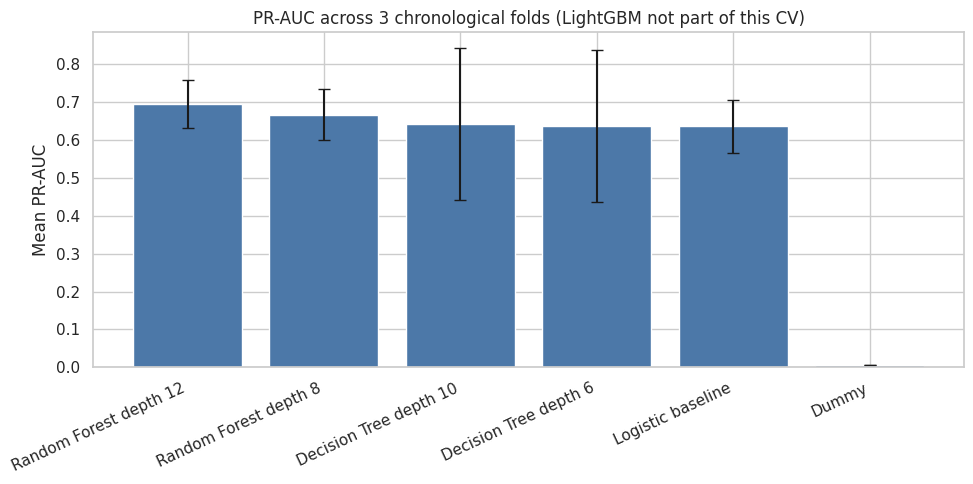

In [ ]:
all_cv_results = {**baseline_results, **tree_results}
cv_summary = pd.DataFrame([{'Model': name, 'Mean PR-AUC': np.mean(s), 'Std PR-AUC': np.std(s),
                            'Fold 1': s[0], 'Fold 2': s[1], 'Fold 3': s[2]} for name, s in all_cv_results.items()]
                          ).sort_values('Mean PR-AUC', ascending=False).reset_index(drop=True)
display(cv_summary.round(4))
plt.figure(figsize=(10, 5))
plt.bar(cv_summary['Model'], cv_summary['Mean PR-AUC'], yerr=cv_summary['Std PR-AUC'], capsize=4, color='#4C78A8')
plt.ylabel('Mean PR-AUC'); plt.title('PR-AUC across 3 chronological folds (LightGBM not part of this CV)')
plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

**Temporal CV summary:** Random Forest depth 12 has the highest mean PR-AUC among the tested tree/forest candidates (0.695), followed by depth 8 (0.667). Decision Trees (about 0.64) and Logistic SGD (0.636) are close, while the dummy baseline is approximately 0.006. Decision Tree results have substantially larger fold-to-fold variability than Random Forest. Differences between models with overlapping variability should not be over-interpreted. LightGBM is not included in this CV comparison.

## 3.2 Validation-Set Comparison

All models on the same validation partition. Thresholds were tuned on this same set, so these numbers support model selection and are **not** the final out-of-sample estimate.

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,Threshold
0,LightGBM,0.9120,0.9973,0.8494,0.8388,0.8441,0.7234
1,LightGBM (tuned),0.9060,0.9971,0.8492,0.8287,0.8388,0.7606
2,Random Forest depth 12,0.7160,0.9809,0.6730,0.6904,0.6816,0.8315
3,Linear SVM (SGD hinge),0.5496,0.9221,0.7163,0.4723,0.5693,1.8220
4,Logistic (SGD),0.5461,0.9219,0.7452,0.4579,0.5673,0.9372
5,Naive Bayes,0.0765,0.8301,0.0943,0.3986,0.1525,0.1116


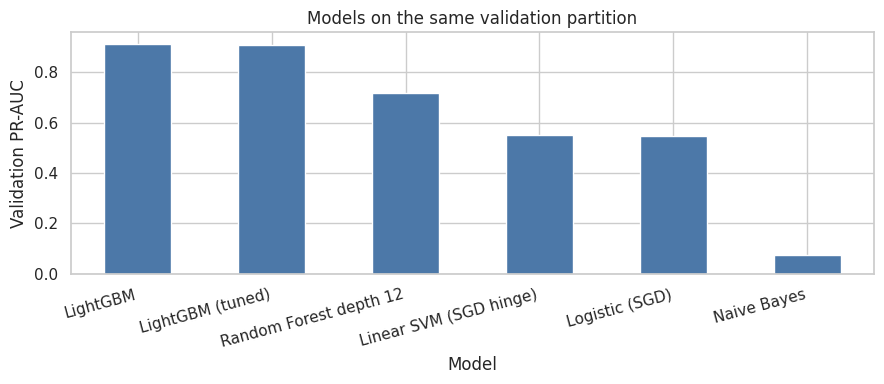

In [ ]:
cols = ['PR-AUC', 'ROC-AUC', 'Precision', 'Recall', 'F1', 'Threshold']
final_comparison = (pd.DataFrame({name: {c: RESULTS[f'{name} · Validation'][c] for c in cols} for name in PROBS}).T
                    .rename_axis('Model').sort_values('PR-AUC', ascending=False).reset_index())
display(final_comparison.round(4))
ax = final_comparison.set_index('Model')['PR-AUC'].plot(kind='bar', figsize=(9, 4), color='#4C78A8')
ax.set_ylabel('Validation PR-AUC'); ax.set_title('Models on the same validation partition')
plt.xticks(rotation=15, ha='right'); plt.tight_layout(); plt.show()


### **Model Evaluation & Selection Report (Validation Set):**

| Model | PR-AUC (Primary Metric) | ROC-AUC | F1-Score | Operational Characteristics |
| :--- | :---: | :---: | :---: | :--- |
| **LightGBM (Default & Tuned)** | **~0.912** | **~0.997** | **~0.844** | **Outstanding Performance.** Catches over 83% of fraudulent attempts while maintaining an exceptionally low false alarm rate (0.17%). |
| **Random Forest (depth=12)** | ~0.716 | ~0.980 | ~0.681 | Good performance, but exhibits heavy training overhead on large datasets unless parallel processing is fully leveraged. |
| **Linear SVM / Logistic SGD** | ~0.550 | ~0.922 | ~0.569 | Blazing fast to train; serves as a strong linear baseline but fails to capture complex non-linear behaviors. |
| **Naive Bayes** | ~0.076 | ~0.830 | ~0.152 | Weakest performer. The high false alarm rate (4.44%) would completely overwhelm an operational review team. |

**Final Recommendation:** The original `LightGBM` is the best-performing candidate on the current validation partition and evaluation protocol. This result does not by itself establish production readiness; test performance, data quality, operational costs, and monitoring requirements also matter.

## 3.3 The Selected Tree Model: Structure and Importance

Split thresholds are in standardised units; with balanced class weights, node proportions are weighted, not raw class rates.

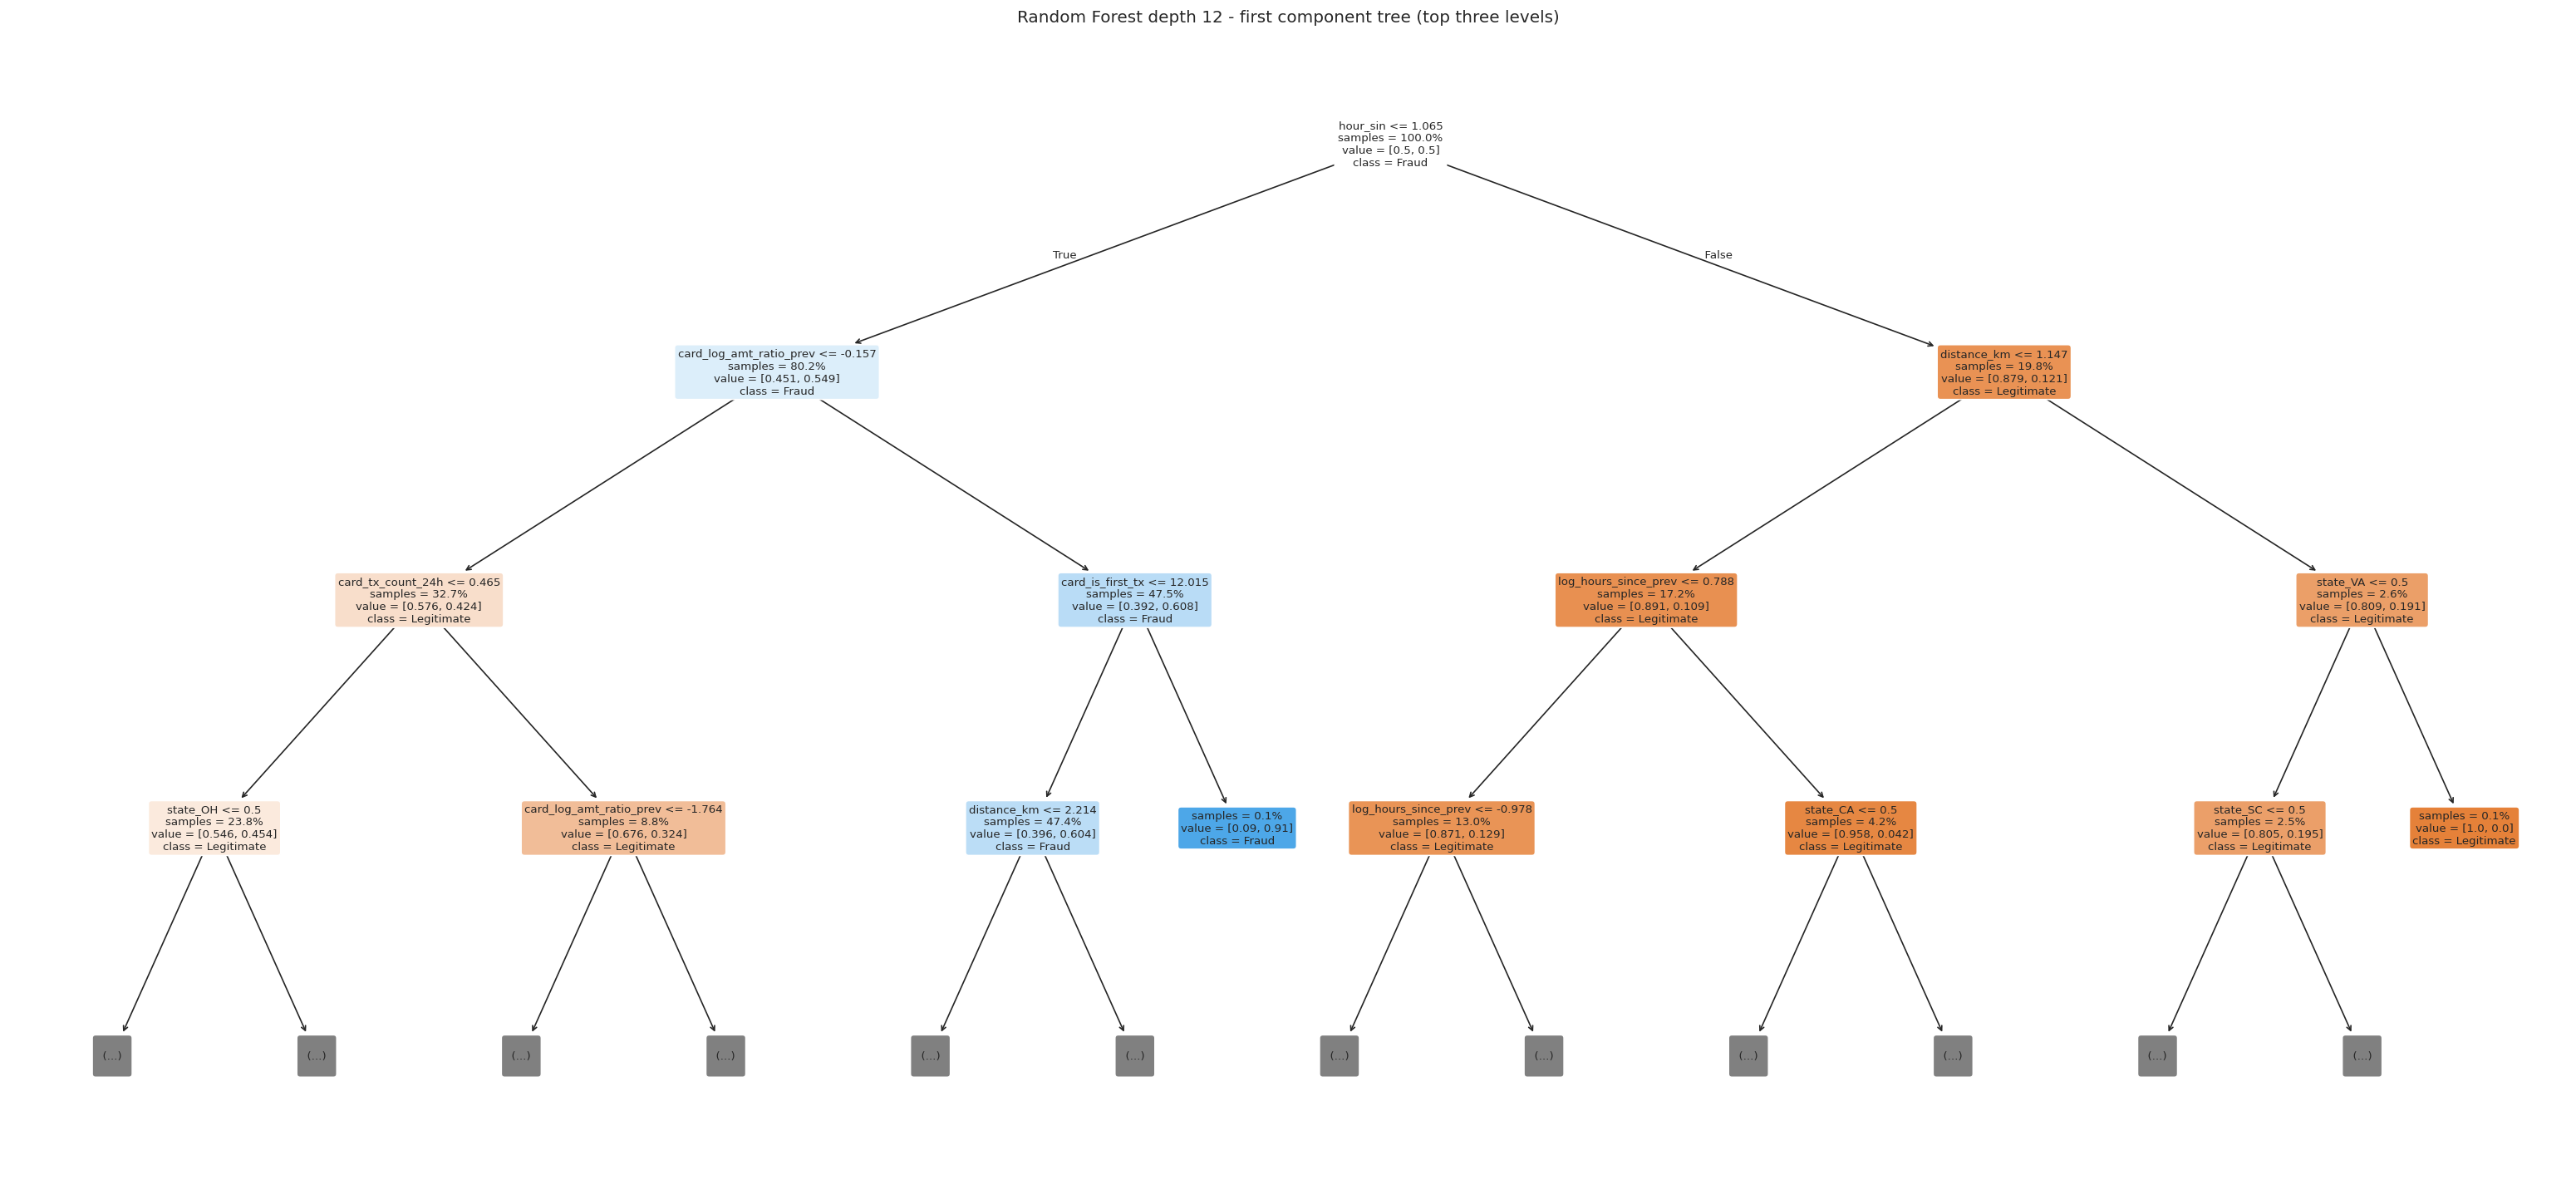

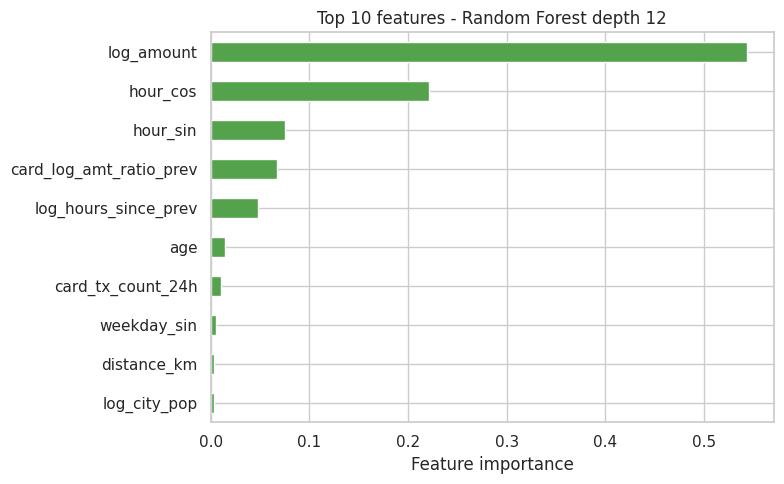

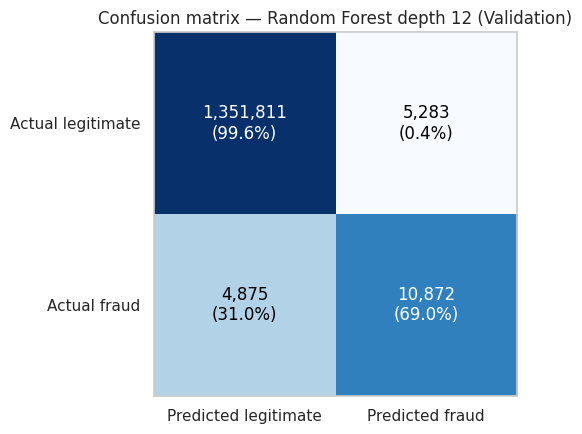

In [ ]:
tree_to_draw = best_tree if isinstance(best_tree, DecisionTreeClassifier) else best_tree.estimators_[0]
plt.figure(figsize=(26, 12), dpi=120)
plot_tree(tree_to_draw, feature_names=FEATURES, class_names=['Legitimate', 'Fraud'], filled=True, rounded=True,
          max_depth=3, impurity=False, proportion=True, fontsize=8)
plt.title(f'{best_tree_name}' + ('' if isinstance(best_tree, DecisionTreeClassifier) else ' - first component tree') + ' (top three levels)')
plt.tight_layout(); plt.show()

importance = pd.Series(best_tree.feature_importances_, index=FEATURES).nlargest(10).sort_values()
importance.plot(kind='barh', figsize=(8, 5), color='#54A24B')
plt.xlabel('Feature importance'); plt.title(f'Top 10 features - {best_tree_name}')
plt.tight_layout(); plt.show()
# Confusion matrix of the selected tree at its validation-chosen threshold.
r = RESULTS[f'{best_tree_name} · Validation']
cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]]); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]:,.0f}\n({cmn[i, j]:.1%})', ha='center', va='center',
                color='white' if cmn[i, j] > .5 else 'black')
ax.set(title=f'Confusion matrix — {best_tree_name} (Validation)', xticks=[0, 1], yticks=[0, 1],
       xticklabels=['Predicted legitimate', 'Predicted fraud'], yticklabels=['Actual legitimate', 'Actual fraud'])
plt.tight_layout(); plt.show()


**Random Forest structure, feature importance, and confusion matrix**

- **Tree illustration:** The visualization shows only the first of 20 trees and the top three levels of a depth-12 tree. Split thresholds are in standardized units, and node proportions are class-weighted. It illustrates individual splits rather than the complete forest's decision process.
- **Feature importance:** `log_amount` (~0.54) is highest, followed by `hour_cos` (~0.22), `hour_sin` (~0.075), `card_log_amt_ratio_prev` (~0.067), and `log_hours_since_prev` (~0.05). The remaining features each contribute less than about 0.02 in this Random Forest importance measure. Impurity-based importance can favour continuous or high-cardinality features.
- **Validation confusion matrix:** The model detects 69.0% of fraud cases, misses 4,875 (31.0%), and flags 5,283 legitimate transactions (0.39%). This is nearly twice the false-alarm count of the original LightGBM on the same validation partition.

## 3.4 SHAP Explanation for LightGBM

SHAP explains which features pushed individual transactions toward or away from a fraud prediction. It uses a random validation sample only.


In [ ]:
try:
    import shap
except ImportError:
    shap = None
    print('SHAP is not installed; skipping the SHAP plot. Install shap before running this cell if needed.')

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


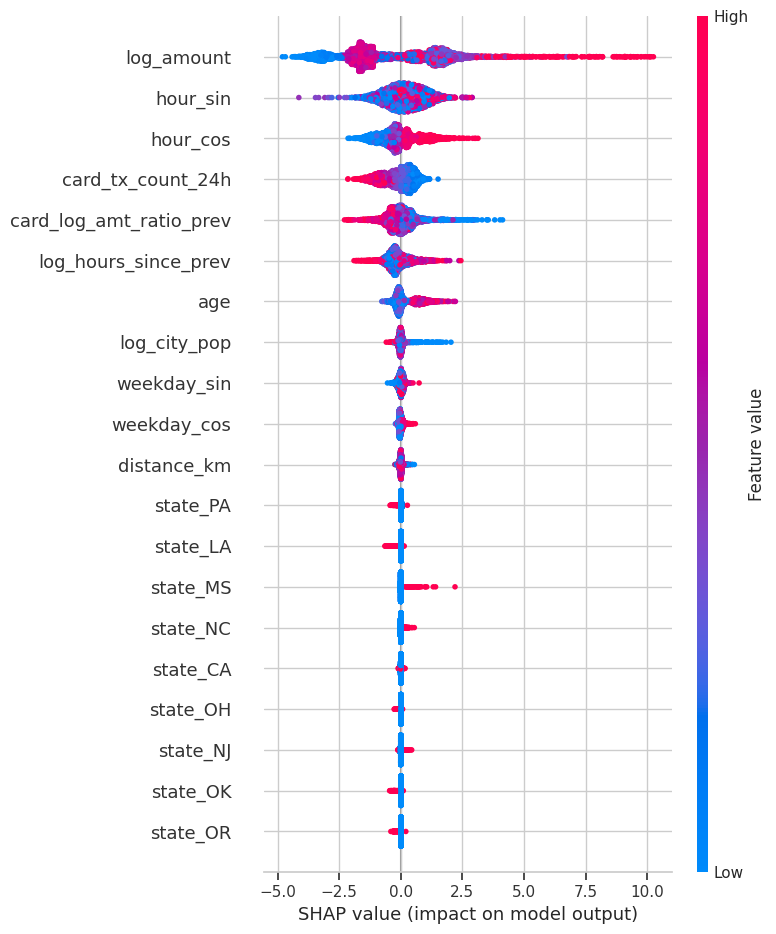

In [ ]:
if shap is not None:
    shap_idx = np.random.default_rng(SEED).choice(len(X_va), size=min(5000, len(X_va)), replace=False)
    X_shap = X_va[shap_idx]
    explainer = shap.TreeExplainer(best_lgb)
    shap_values = explainer.shap_values(X_shap)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    shap.summary_plot(shap_values, X_shap, feature_names=FEATURES, show=True)

**SHAP interpretation (5,000 validation samples)**

- The displayed SHAP ranking places `log_amount` first, followed by the cyclic hour features and card-history features; state indicators and `distance_km` have relatively small contributions in this sample.
- High `log_amount` values generally push the model score upward, while low values often push it downward. The mixed pattern in the middle range is consistent with a non-monotonic relationship in the observed data.
- Higher `card_tx_count_24h` values tend to push the score downward in the displayed sample. `card_log_amt_ratio_prev` shows values on both sides of zero, suggesting that its contribution depends on other feature values.
- `log_city_pop` shows a modest conditional contribution even though its univariate class distributions look similar. This is not evidence of a causal relationship.
- Small SHAP contributions from state features do not, by themselves, establish that these features are noise or should be removed.
- **Model scope:** The current SHAP and gain visualizations explain `best_lgb` (the tuned LightGBM), whereas the final selected model is the original LightGBM. Interpret these plots as explanations of the tuned model, not as a verified explanation of the final selected model.

> **Reading SHAP:** Positive SHAP values push the model output toward the fraud class and negative values push it away from the fraud class. The direction is relative to the model output being explained; it does not establish causation. The plots shown here explain the tuned LightGBM model.


# 4. Final Test Evaluation and Conclusions

## 4.1 Final Test Evaluation

With `RUN_FINAL_TEST = True` the model with the best validation PR-AUC is scored on the test partition **once**, using the threshold frozen on validation. Do not use these scores to keep tuning.


In [ ]:
if RUN_FINAL_TEST:
    # Select once using validation PR-AUC; the test set is used only after this decision.
    final_model_name = max(PROBS, key=lambda name: RESULTS[f'{name} · Validation']['PR-AUC'])
    final_threshold = float(RESULTS[f'{final_model_name} · Validation']['Threshold'])
    X_te, y_te = load('test')
    print(f'Test: {X_te.shape[0]:,} rows | fraud rate {y_te.mean():.2%}')
    p_te = SCORERS[final_model_name](X_te)
    evaluate(f'{final_model_name} · Test', y_te, p_te, final_threshold)
    print(f'Final model: {final_model_name} | threshold frozen from validation: {final_threshold:.6f}')
    # Business-cost view on test, with both thresholds frozen on validation.
    amt_te = pd.read_parquet(OUT / 'test_row_index.parquet', columns=['amt'])['amt'].to_numpy(float)
    no_model_te = float(amt_te[y_te == 1].sum())
    rows = []
    for label, thr in [('F1-optimal threshold', THR[final_model_name]['f1']),
                       ('Cost-optimal threshold', THR[final_model_name]['cost'])]:
        total, missed, alarms = total_cost(y_te, p_te, amt_te, thr)
        rows.append({'Threshold rule': label, 'Missed-fraud amount': missed, 'False-alarm cost': alarms,
                     'Total cost': total, 'No-model cost': no_model_te,
                     'Savings vs no model (%)': (no_model_te - total) / no_model_te * 100})
    test_costs = pd.DataFrame(rows).set_index('Threshold rule')
    display(test_costs.style.format({c: '{:,.0f}' for c in test_costs.columns[:4]} | {'Savings vs no model (%)': '{:.1f}'})
            .set_caption(f'Test cost with assumed false-alarm cost = {COST_FP:,.0f}'))


Test: 1,716,052 rows | fraud rate 1.22%

========== LightGBM · Test ==========
ROC-AUC 0.9966 | PR-AUC 0.9050 | threshold 0.7234
Precision 0.8332 | Recall 0.8344 | F1 0.8338
                   Pred: legit   Pred: fraud
Actual: legit        1,691,603         3,499
Actual: fraud            3,470        17,480
=> caught 17,480/20,950 frauds (83.4%) with 3,499 false alarms among 1,695,102 legitimate transactions (0.21%).
Final model: LightGBM | threshold frozen from validation: 0.723404


,Missed-fraud amount,False-alarm cost,Total cost,No-model cost,Savings vs no model (%)
Threshold rule,,,,,
F1-optimal threshold,"767,523","157,455","924,978","11,355,799",91.9
Cost-optimal threshold,"324,562","373,995","698,557","11,355,799",93.8


In [ ]:
order = ['PR-AUC', 'ROC-AUC', 'Precision', 'Recall', 'F1', 'Threshold', 'TP', 'FP', 'FN']
fmt = {c: '{:.4f}' for c in order[:6]}
fmt.update({c: '{:,.0f}' for c in ['TP', 'FP', 'FN']})
summary = pd.DataFrame(RESULTS).T[order]
is_test = summary.index.str.endswith('· Test')
def styled(frame, caption):
    return frame.style.format(fmt).background_gradient(subset=['PR-AUC', 'F1'], cmap='Blues').set_caption(caption)
display(styled(summary[~is_test], 'Validation results (PR-AUC is the primary metric)'))
if is_test.any():
    display(styled(summary[is_test], 'Held-out test result (threshold frozen on validation)'))


,PR-AUC,ROC-AUC,Precision,Recall,F1,Threshold,TP,FP,FN
Logistic (SGD) · Validation,0.5461,0.9219,0.7452,0.4579,0.5673,0.9372,"7,211","2,466","8,536"
LightGBM · Validation,0.9120,0.9973,0.8494,0.8388,0.8441,0.7234,"13,208","2,341","2,539"
LightGBM (tuned) · Validation,0.9060,0.9971,0.8492,0.8287,0.8388,0.7606,"13,050","2,318","2,697"
Naive Bayes · Validation,0.0765,0.8301,0.0943,0.3986,0.1525,0.1116,"6,277","60,297","9,470"
Linear SVM (SGD hinge) · Validation,0.5496,0.9221,0.7163,0.4723,0.5693,1.8220,"7,438","2,946","8,309"
Random Forest depth 12 · Validation,0.7160,0.9809,0.6730,0.6904,0.6816,0.8315,"10,872","5,283","4,875"


,PR-AUC,ROC-AUC,Precision,Recall,F1,Threshold,TP,FP,FN
LightGBM · Test,0.9050,0.9966,0.8332,0.8344,0.8338,0.7234,"17,480","3,499","3,470"


**Validation and test summary:** The notebook reports validation metrics for all candidate models, but test metrics only for the original LightGBM. This is a deliberate final-evaluation design, so test performance cannot be compared across all candidate models. PR-AUC (implemented as average precision) is reported alongside threshold-dependent metrics because fraud is rare.

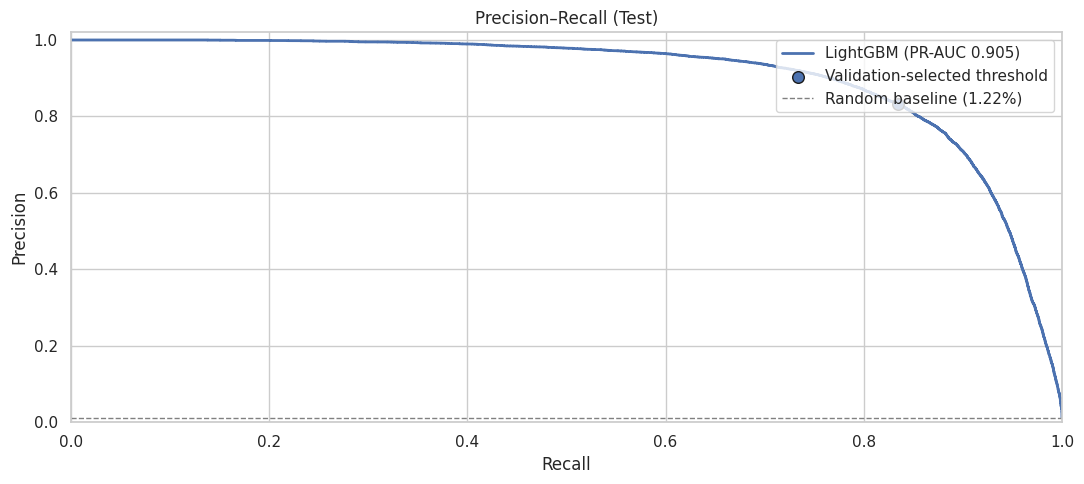

In [ ]:
if RUN_FINAL_TEST:
    name = f'{final_model_name} · Test'
    pr, rc, _ = precision_recall_curve(y_te, p_te)
    r = RESULTS[name]
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(rc, pr, lw=2, label=f'{final_model_name} (PR-AUC {r["PR-AUC"]:.3f})')
    ax.scatter(r['Recall'], r['Precision'], s=70, edgecolor='k', zorder=3,
               label='Validation-selected threshold')
    ax.axhline(y_te.mean(), ls='--', c='gray', lw=1, label=f'Random baseline ({y_te.mean():.2%})')
    ax.set(title='Precision–Recall (Test)', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

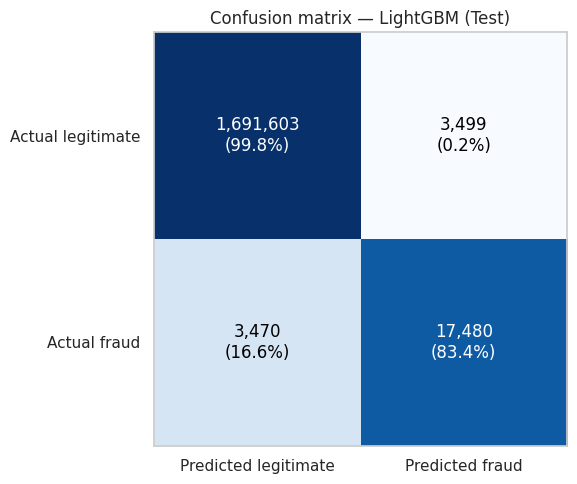

In [ ]:
if RUN_FINAL_TEST:
    r = RESULTS[f'{final_model_name} · Test']
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]])
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,.0f}\n({cmn[i, j]:.1%})', ha='center', va='center',
                    color='white' if cmn[i, j] > .5 else 'black', fontsize=12)
    ax.set(title=f'Confusion matrix — {final_model_name} (Test)', xticks=[0, 1], yticks=[0, 1],
           xticklabels=['Predicted legitimate', 'Predicted fraud'], yticklabels=['Actual legitimate', 'Actual fraud'])
    plt.tight_layout(); plt.show()

**Test confusion matrix (row-normalized)**

The model correctly classifies 1,691,603 legitimate transactions (about 99.8%) and incorrectly flags 3,499 (about 0.2%). Of the 20,950 fraudulent transactions, it detects 17,480 (83.4%) and misses 3,470 (16.6%). These results use the threshold selected on validation and frozen before test scoring. A cost-based threshold may be preferable for a particular operation, but it should be selected using validation or a separate calibration set, not by tuning on the test results.

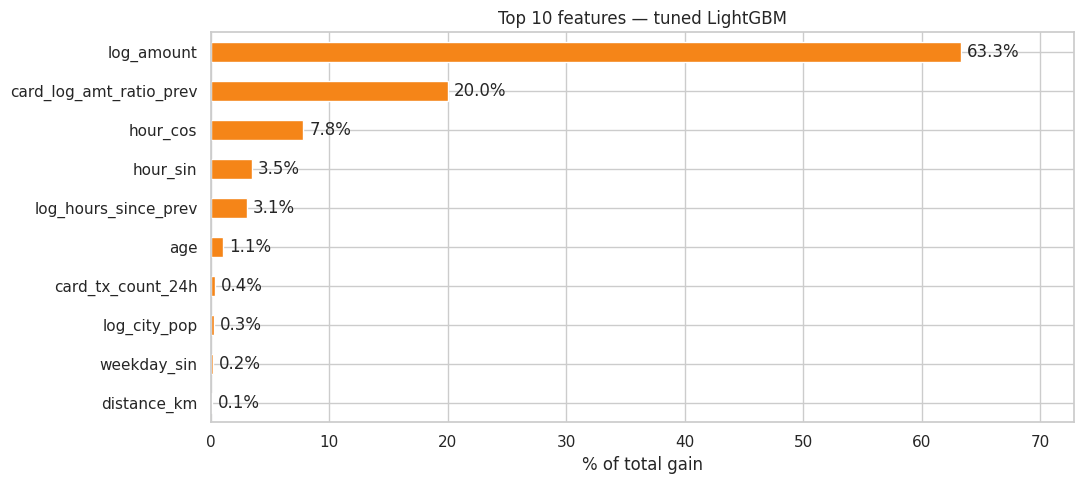

In [ ]:
# Gain-based feature importance of the tuned LightGBM (shown even when another model is final).
gain = pd.Series(best_lgb.feature_importance('gain'), index=FEATURES)
if gain.sum() > 0:
    gain = (gain / gain.sum() * 100).nlargest(10).sort_values()
    fig, ax = plt.subplots(figsize=(11, 5))
    gain.plot.barh(ax=ax, color='#F58518')
    for k, v in enumerate(gain):
        ax.text(v + .5, k, f'{v:.1f}%', va='center')
    ax.set(title='Top 10 features — tuned LightGBM', xlabel='% of total gain', xlim=(0, gain.max() * 1.15))
    plt.tight_layout(); plt.show()

## 4.2 Conclusions

The key numbers below are generated from this run, so they always match the tables above.


In [ ]:
lines = []
best = final_comparison.iloc[0]
base = final_comparison[final_comparison['Model'].str.contains('Logistic')].iloc[0]
lines.append(f"- **Best model on validation:** {best['Model']} — PR-AUC {best['PR-AUC']:.3f}, recall {best['Recall']:.1%}, "
             f"precision {best['Precision']:.1%} at the F1-optimal threshold (logistic baseline PR-AUC: {base['PR-AUC']:.3f}).")
lines.append(f"- **Cost view (validation):** with an assumed false-alarm cost of {COST_FP:,.0f}, the cost-optimal threshold removes "
             f"{val_costs.loc[best['Model'], 'Savings vs no model (%)']:.1f}% of the loss of having no model "
             f"(see the sensitivity table in Section 2.7).")
if RUN_FINAL_TEST:
    r = RESULTS[f'{final_model_name} · Test']
    lines.append(f"- **Held-out test ({final_model_name}):** PR-AUC {r['PR-AUC']:.3f}, recall {r['Recall']:.1%}, precision {r['Precision']:.1%}, "
                 f"{r['FP']:,} false alarms; cost saving vs no model {test_costs.loc['Cost-optimal threshold', 'Savings vs no model (%)']:.1f}% "
                 f"at the cost-optimal threshold.")
gain_top = pd.Series(best_lgb.feature_importance('gain'), index=FEATURES)
gain_top = (gain_top / gain_top.sum() * 100).nlargest(3)
lines.append('- **Most important features (tuned LightGBM, gain):** ' + ', '.join(f'`{k}` ({v:.1f}%)' for k, v in gain_top.items()) + '.')
abl = ablation.loc[('random 75/25', 'our features + category, month, day'), 'PR-AUC']
abl_t = ablation.loc[('chronological 75/25', 'our features + category, month, day'), 'PR-AUC']
lines.append(f"- **Why a chronological split:** adding category/month/day gives PR-AUC {abl:.2f} under a random split but only {abl_t:.2f} chronologically, "
             "so random-split scores are not comparable with a realistic deployment.")
display(Markdown('\n'.join(lines)))


- **Best model on validation:** LightGBM — PR-AUC 0.912, recall 83.9%, precision 84.9% at the F1-optimal threshold (logistic baseline PR-AUC: 0.546).
- **Cost view (validation):** with an assumed false-alarm cost of 45, the cost-optimal threshold removes 94.2% of the loss of having no model (see the sensitivity table in Section 2.7).
- **Held-out test (LightGBM):** PR-AUC 0.905, recall 83.4%, precision 83.3%, 3,499 false alarms; cost saving vs no model 93.8% at the cost-optimal threshold.
- **Most important features (tuned LightGBM, gain):** `log_amount` (63.3%), `card_log_amt_ratio_prev` (20.0%), `hour_cos` (7.8%).
- **Why a chronological split:** adding category/month/day gives PR-AUC 0.98 under a random split but only 0.60 chronologically, so random-split scores are not comparable with a realistic deployment.

## 4.3 Limitations and Next Steps

- **Assumed costs:** The false-alarm cost is a scenario assumption, and the currency of `amt` is unconfirmed. Reported savings are model-based estimates rather than measured operational savings.
- **Repeated validation use:** Validation supports early stopping, model selection, and threshold selection, so validation scores may be optimistic. The test partition provides a more independent estimate only to the extent that it has not informed earlier project decisions.
- **Partial temporal CV:** Cross-validation covers only the most recent `N_CV` training rows and only selected tree/forest candidates and baselines. LightGBM is evaluated and tuned separately using validation.
- **Temporal drift:** Fraud prevalence rises across the chronological partitions, and patterns may change further. Rolling evaluation and periodic retraining are reasonable next steps.
- **Dataset provenance:** Some categories contain no legitimate examples in training, suggesting possible synthetic or generator-specific patterns. Results may not transfer directly to real banking data; the source timezone is also unknown.
- **Further work:** Evaluate probability calibration on a separate calibration split, verify the point-in-time definitions of source features, test merchant-side history features, and include LightGBM in temporal cross-validation.

In [ ]:
pd.DataFrame(RESULTS).T.to_csv(results_dir / 'model_metrics.csv')
cv_summary.to_csv(results_dir / 'temporal_cv_results.csv', index=False)
final_comparison.to_csv(results_dir / 'validation_comparison.csv', index=False)
val_costs.to_csv(results_dir / 'validation_cost_comparison.csv')
cost_sensitivity.to_csv(results_dir / 'validation_cost_sensitivity.csv')
ablation.to_csv(results_dir / 'protocol_ablation.csv')
if RUN_FINAL_TEST:
    test_costs.to_csv(results_dir / 'test_cost_comparison.csv')
run_info = {
    'eda_scope': 'train_only',
    'final_test_evaluated': RUN_FINAL_TEST,
    'source_sha256': input_manifest['source_sha256'],
    'split_sizes': {k: int(b-a) for k, (a,b) in slices.items()},
    'selected_model': final_model_name if RUN_FINAL_TEST else None,
    'cost_fp_assumption': COST_FP,
    'versions': dict(settings['versions'], lightgbm=lgb.__version__)
}
with open(results_dir / 'run_info.json', 'w', encoding='utf-8') as file:
    json.dump(run_info, file, indent=2)